In [17]:
import icarusplot
import uproot
import pandas as pd
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import os
from scipy.stats import chi2
from scipy.stats import norm
import VariableInfoMap
import DataEntryInfoMap
from SelectionInfo import SelectionInfo
from BaseInfo import BaseInfo
from CalcInclusiveXsecError import CalcInclusiveXsecError
import CrossSectionPlotHelper
from CrossSectionToyUtil import CalcXsecFromThrows

In [18]:
WD = '/Users/jskim/Documents/Neutrino/ICARUS/GUNDAM-1.9.X/work/run_configs/260311_LogNormal'

In [19]:
# Pre-defined info map
variableInfos = VariableInfoMap.VariableInfos

In [20]:
JobName = '250627_BadRegionRejection'

In [21]:
FitOutputBaseDir = f'{WD}/output/{JobName}/Fitter'
ToyOutputBaseDir = f'{WD}/output/{JobName}/ToyGenerator'
XsecOutputBaseDir = f'{WD}/output/{JobName}/CalcXsec'

In [22]:
NVariables = 2 # Number of sim-fitted variables

In [23]:
FitSets = [
    ['Angular', 'SimFit_StatCovariance', ['MuonCos','MuonProtonCos']],
    # ['TKI', 'SimFit_MuonPLT0p8_StatCovariance', ['deltaPT','deltaalphaT']],
]

In [24]:
FitDataType = 'RealData'
# FitDataType = 'Asimov'

POTToNormalize = 2.5e20

In [25]:
OutputBaeDir = f'{WD}/CombinedPlotForPaper/{FitDataType}'
os.system(f'mkdir -p {OutputBaeDir}')

0

In [26]:
output_CalcXsecFromThrows = []

for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    IsMuonPCutApplied = ('MuonPLT0p8' in FitConfigType)
    PhaseSpaceCut = 'AllSignal'
    if IsMuonPCutApplied:
        PhaseSpaceCut = 'MuonPLT0p8'

    XsecFilepath = f'{XsecOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'

    output_CalcXsecFromThrows.append( CalcXsecFromThrows(XsecFilepath, VarType) )

# p-value table

In [27]:
# theory
TheoryXsecBaseDir = '/Users/jskim/docker/volumes/nusyst/work/250605_ReworkGeneratorPrediction/xsecs'

In [28]:
ModeCategories = [
    ['0', 'QE', '#0072B2'],
    ['10', 'MEC', '#E69F00'],
    ['1', 'RES', '#009E73'],
    ['2', 'DIS', '#56B4E9'],
]

In [29]:
GeneratorSetName = 'AllGenerators'
GeneratorInfos = [
    ['GENIE', '250611_GENIE_1MEvents', 'AR23_20i_00_000', 'Reference model'],
    ['GENIE', '260123_3_04_00_AR23_FASeries', 'AR23_20i_02_000', 'LQCD '+r'$z$'+'-exp '+r'$F_{A}^{CCQE}$'],
    ['GENIE', '260123_3_04_00_AR23_FASeries', 'AR23_20i_01_000', 'MINERvA '+r'$z$'+'-exp '+r'$F_{A}^{CCQE}$'],
    # ['GENIE', '251006_GENIE_100kEvents', 'G18_10b_02_11b', 'hN2018 FSI'],
    ['GENIE', '260604_3_04_00_AR23_hN2018', 'AR23_20b_00_000', 'hN2018 FSI'],
    ['NEUT', '260510_NEUT_Regen', '6.1.3', 'NEUT'],
    ['NuWro', '251202_NuWro_BaseCard_1MEvents', '25.11', 'NuWro'],
    ['GiBUU', '250728_GiBUU_MoreStatsFromEAF', 'r2025_02', 'GiBUU'],
]

In [30]:
UseXsecToyUtil = True

# chi2 table
arr_chi2s = []
arr_pvals = []
arr_NDOFs = []

for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    IsMuonPCutApplied = ('MuonPLT0p8' in FitConfigType)
    PhaseSpaceCut = 'AllSignal'
    if IsMuonPCutApplied:
        PhaseSpaceCut = 'MuonPLT0p8'

    XsecFilepath = f'{XsecOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'

    # xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = CalcXsecFromThrows(XsecFilepath, VarType)
    xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = output_CalcXsecFromThrows[i_FitSet]

    # Getting the cross-section binning fist
    xsec_Binnings_Extraction = []
    for i_Variable, VariableName in enumerate(VariableNames):
        TrueVariableName = f'True{VariableName}'
        with uproot.open(XsecFilepath) as f:
            # To get the binning
            h_for_binning = f[f'calcXsec/plots/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}/{TrueVariableName}/MC_TH1D']
            Binnings_Extraction = h_for_binning.to_numpy()[1]
            xsec_Binnings_Extraction.append(Binnings_Extraction)


    # Quick read/save for chi2 calculation before the plotting
    arr_xsec_theory_AnaBin = []
    for i_G, GeneratorInfo in enumerate(GeneratorInfos):

        GeneratorName = GeneratorInfo[0]
        GeneratorJobName = GeneratorInfo[1]
        GeneratorConfig = GeneratorInfo[2]
        GeneratorLatex = GeneratorInfo[3]

        this_arr_xsec_theory_AnaBin = np.array([])

        for i_Variable, VariableName in enumerate(VariableNames):

            TrueVariableName = f'True{VariableName}'

            Binnings_Extraction = xsec_Binnings_Extraction[i_Variable]

            # Ana binning
            TheoryBinType = 'AnaBin'
            this_csv = f'{TheoryXsecBaseDir}/xsec_{PhaseSpaceCut}_{GeneratorName}_{GeneratorConfig}_{GeneratorJobName}_True{VariableName}_{TheoryBinType}.csv'
            this_df = pd.read_csv(this_csv)
            BinCenters_Theory, BinErrors_Theory, h_Theory_AnaBin = this_df['x_center'].to_numpy(), this_df['x_err'].to_numpy(), this_df['xsec'].to_numpy()

            Binnings_Theory = BinCenters_Theory - BinErrors_Theory
            Binnings_Theory = np.append( Binnings_Theory, BinCenters_Theory[-1]+BinErrors_Theory[-1] )

            # Validate the binning
            if not np.allclose(Binnings_Theory, Binnings_Extraction):
                print('Extraction:', Binnings_Extraction)
                print(f'{GeneratorName}:', Binnings_Theory)
                raise ValueError(f'{GeneratorName} has wrong binning')
            
            this_arr_xsec_theory_AnaBin = np.append(this_arr_xsec_theory_AnaBin, h_Theory_AnaBin)

        arr_xsec_theory_AnaBin.append(this_arr_xsec_theory_AnaBin)

    arr_xsec_theory_AnaBin = np.array(arr_xsec_theory_AnaBin)

    with uproot.open(XsecFilepath) as f:

        # Covariance
        uph_Cov = f['calcXsec/matrices/covarianceMatrix_TH2D']

        # Decide which Cov to use
        # xsec_Cov: (XSecBins, XSecBins)
        xsec_Cov = uph_Cov.to_numpy()[0] if (not UseXsecToyUtil) else xsec_cov_log
        xsec_InvCov = np.linalg.inv(xsec_Cov)

        # xsec_diff: (Generator, XSecBins)
        xsec_diff = xsec_bestfit_vals - arr_xsec_theory_AnaBin if (not UseXsecToyUtil) else np.log(xsec_bestfit_vals) - np.log(arr_xsec_theory_AnaBin)

        xsec_chi2s_Generators = np.einsum('Gi, ij, Gj -> G', xsec_diff, xsec_InvCov, xsec_diff)
        xsec_pvalues_Generators = np.array([1 - chi2.cdf(xsec_chi2_Generators, len(xsec_bestfit_vals)) for xsec_chi2_Generators in xsec_chi2s_Generators])

    arr_chi2s.append(xsec_chi2s_Generators)
    arr_pvals.append(xsec_pvalues_Generators)
    arr_NDOFs.append(len(xsec_bestfit_vals))

# arr_chi2s = []
# arr_pvals = []
# arr_NDOFs = []

for i_G, GeneratorInfo in enumerate(GeneratorInfos):

    GeneratorName = GeneratorInfo[0]
    GeneratorJobName = GeneratorInfo[1]
    GeneratorConfig = GeneratorInfo[2]
    GeneratorLatex = GeneratorInfo[3]

    out = GeneratorLatex

    for i_FitSet, FitSet in enumerate(FitSets):

        VarType = FitSet[0]
        FitConfigType = FitSet[1]
        VariableNames = FitSet[2]

        VariableXName = VariableNames[0]
        VariableYName = VariableNames[1]

        out += ' & %1.2f/%d & %1.3f' %(arr_chi2s[i_FitSet][i_G], arr_NDOFs[i_FitSet], arr_pvals[i_FitSet][i_G])

    out += ' \\\\'

    print(out)



Reference model & 13.44/18 & 0.765 \\
LQCD $z$-exp $F_{A}^{CCQE}$ & 7.27/18 & 0.988 \\
MINERvA $z$-exp $F_{A}^{CCQE}$ & 9.40/18 & 0.950 \\
hN2018 FSI & 12.79/18 & 0.804 \\
NEUT & 23.02/18 & 0.190 \\
NuWro & 17.34/18 & 0.500 \\
GiBUU & 15.88/18 & 0.601 \\


In [15]:
for i_G, GeneratorInfo in enumerate(GeneratorInfos):

    GeneratorName = GeneratorInfo[0]
    GeneratorJobName = GeneratorInfo[1]
    GeneratorConfig = GeneratorInfo[2]
    GeneratorLatex = GeneratorInfo[3]

    out = GeneratorLatex

    for i_FitSet, FitSet in enumerate(FitSets):

        VarType = FitSet[0]
        FitConfigType = FitSet[1]
        VariableNames = FitSet[2]

        VariableXName = VariableNames[0]
        VariableYName = VariableNames[1]

        this_pval = arr_pvals[i_FitSet][i_G]

        this_sigma = abs(norm.ppf(this_pval/2., loc=0, scale=1))

        out += ',%1.3f'%(this_sigma)

    print(out)


Reference model,0.299,0.033
LQCD $z$-exp $F_{A}^{CCQE}$,0.016,0.037
MINERvA $z$-exp $F_{A}^{CCQE}$,0.063,0.024
hN2018 FSI,0.248,0.048
NEUT,1.311,0.080
NuWro,0.675,0.998
GiBUU,0.523,0.950


# GENIE Breakdown

In [16]:
XsecPlotDir = f'{OutputBaeDir}/xsec'
os.system(f'mkdir -p {XsecPlotDir}')

0

In [17]:
GeneratorName = 'GENIE'
GeneratorJobName = '250611_GENIE_1MEvents'
GeneratorConfig = 'AR23_20i_00_000'
GeneratorLatex = 'Reference model'

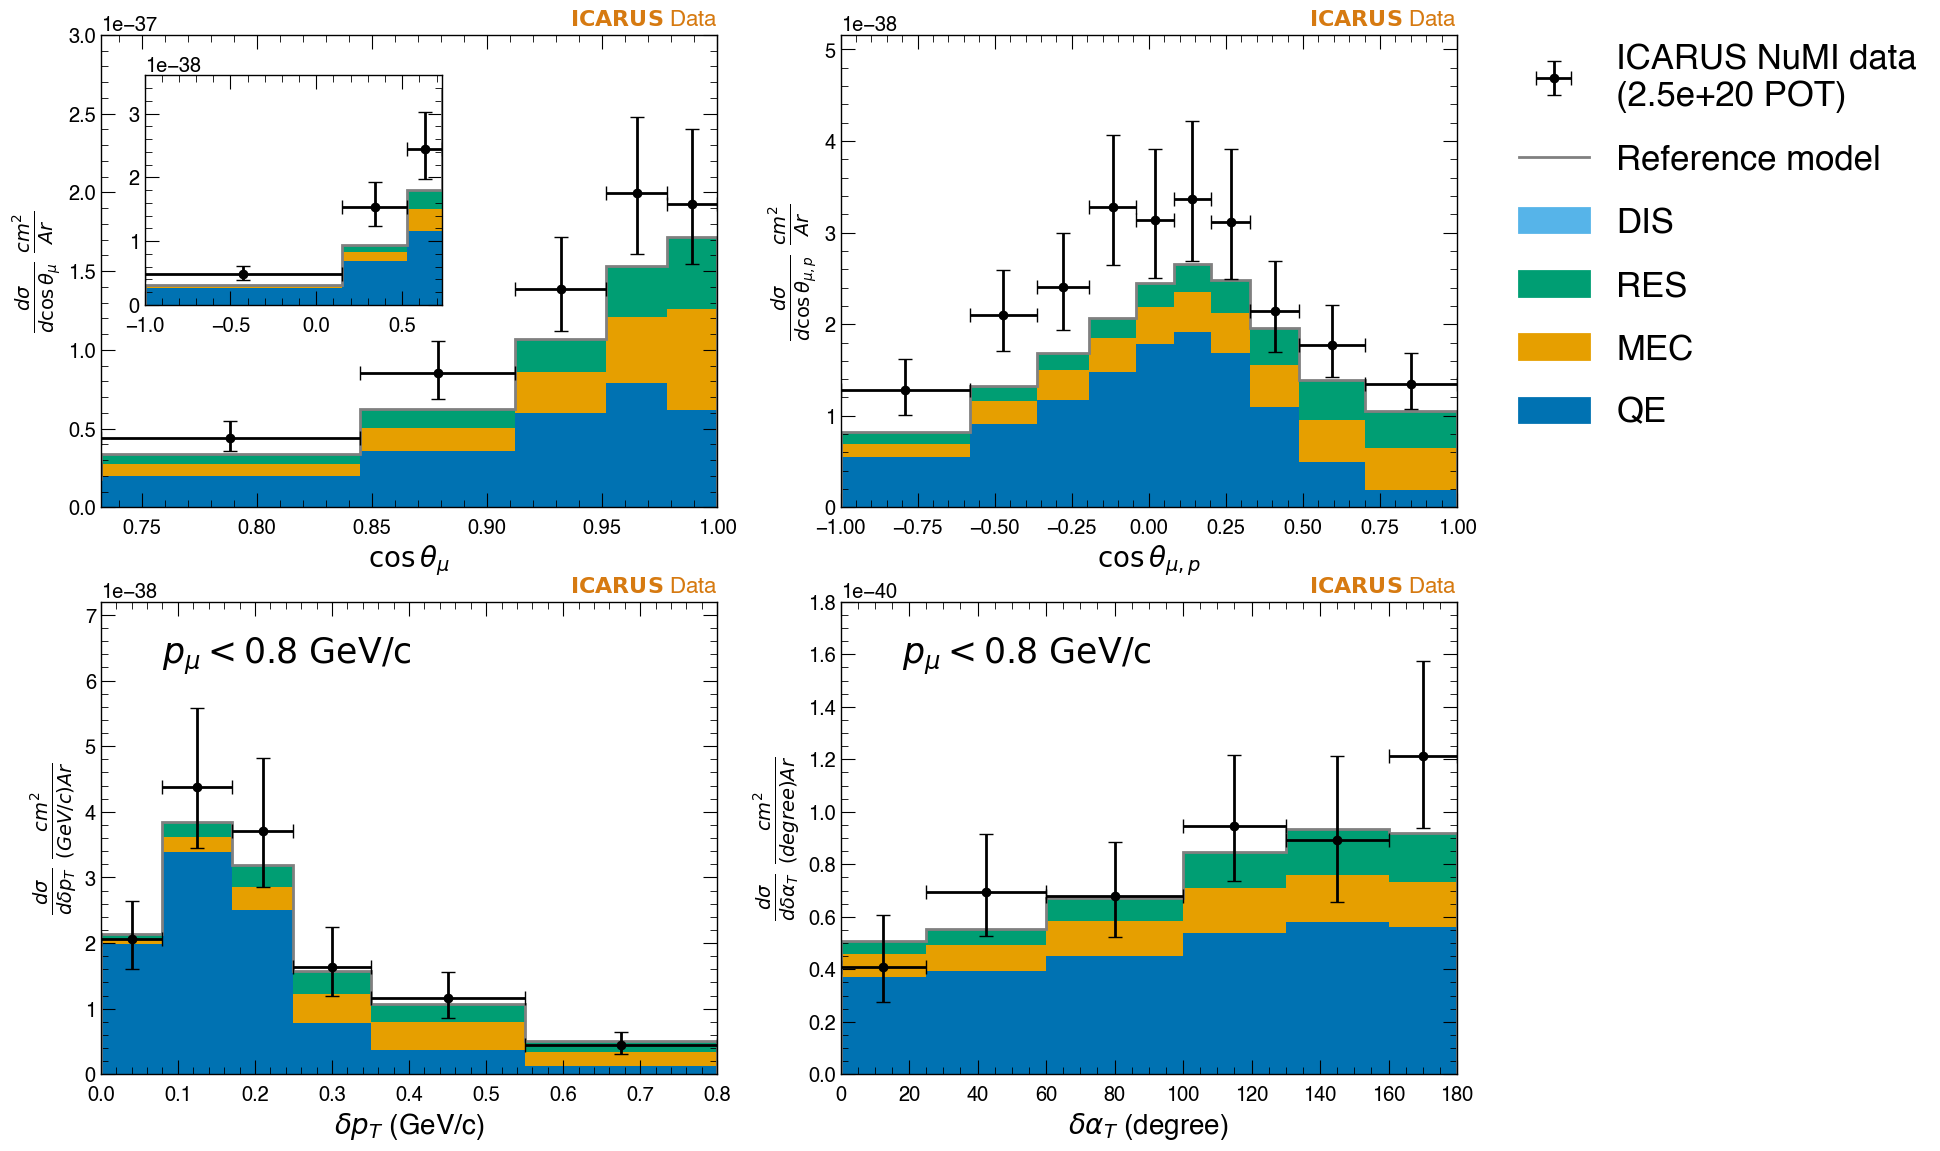

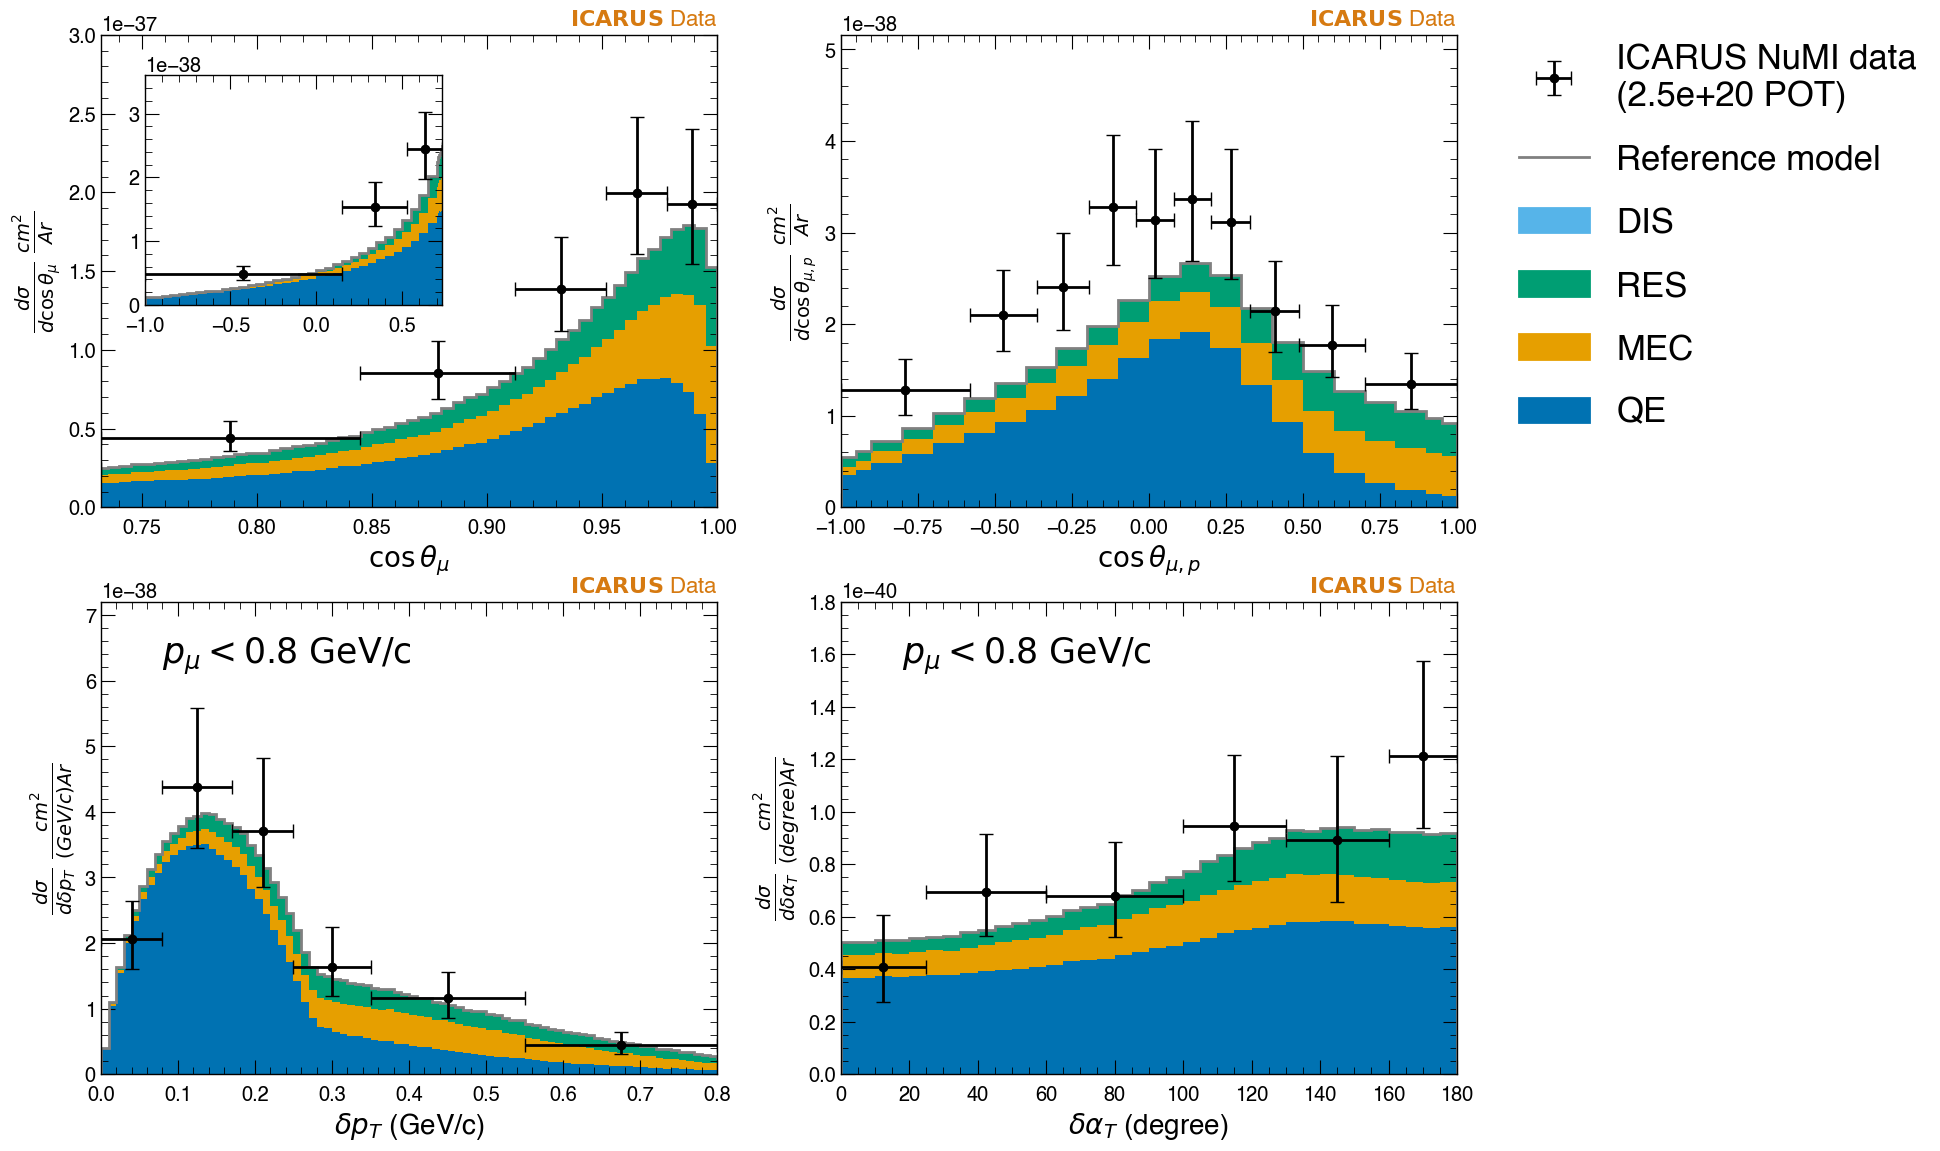

In [18]:
fig_GENIEBreakdown_AnaBin, ax_GENIEBreakdown_AnaBin = plt.subplots(
    ncols=NVariables,
    nrows=2,
    figsize=(8*NVariables+1.5,2*6+1.5)
)
fig_GENIEBreakdown_FineBin, ax_GENIEBreakdown_FineBin = plt.subplots(
    ncols=NVariables,
    nrows=2,
    figsize=(8*NVariables+1.5,2*6+1.5)
)

lgs_BreakDown = []

for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    IsMuonPCutApplied = ('MuonPLT0p8' in FitConfigType)
    PhaseSpaceCut = 'AllSignal'
    if IsMuonPCutApplied:
        PhaseSpaceCut = 'MuonPLT0p8'

    XsecFilepath = f'{XsecOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'
    # xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = CalcXsecFromThrows(XsecFilepath, VarType)
    xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = output_CalcXsecFromThrows[i_FitSet]

    for i_Variable, VariableName in enumerate(VariableNames):

        TrueVariableName = f'True{VariableName}'
        IsMuonCosPlot = ('MuonCos' in VariableName)

        variableInfo = variableInfos[TrueVariableName]
        VariableXTitle = variableInfo.GetXaxisTitle()
        xMin = variableInfo.xMin
        xMax = variableInfo.xMax

        VariableYTitle = CrossSectionPlotHelper.GetCrossSectionTitle(TrueVariableName)
        VariableYMax = CrossSectionPlotHelper.GetCrossSectionYMax(TrueVariableName, PhaseSpaceCut)

        SubCovIndices = xsec_SubIndices[i_Variable]

        # 1) Using the upper side
        xsec_OneSig_XsecToyUtil = [xsec_dn_err[SubCovIndices], xsec_up_err[SubCovIndices]]

        # Extraction
        
        with uproot.open(XsecFilepath) as f:

            # To get the binning
            h_for_binning = f[f'calcXsec/plots/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}/{TrueVariableName}/MC_TH1D']
            Binnings_Extraction = h_for_binning.to_numpy()[1]
            BinCenters_Extraction = [
                (Binnings_Extraction[i]+Binnings_Extraction[i+1])/2.
                for i in range(len(Binnings_Extraction)-1)
            ]
            BinErrors_Extraction = [
                (Binnings_Extraction[i+1]-Binnings_Extraction[i])/2.
                for i in range(len(Binnings_Extraction)-1)
            ]

            # x-sec hist
            uh_Extraction = f[f'calcXsec/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}_TH1D']
            h_Extraction = uh_Extraction.to_numpy()[0]
            h_Extraction_err = uh_Extraction.errors() if (not UseXsecToyUtil) else xsec_OneSig_XsecToyUtil

        # GENIE Prediction

        # 1) Ana binning

        if IsMuonCosPlot:

            y_boundary = 0.7320
            y_max_zoom = 0.12

            ax_GENIEBreakdown_AnaBin_zoom = fig_GENIEBreakdown_AnaBin.add_axes([0.15, 0.68, 0.17, 0.17])

        TheoryBinType = 'AnaBin'
        this_csv = f'{TheoryXsecBaseDir}/xsec_{PhaseSpaceCut}_{GeneratorName}_{GeneratorConfig}_{GeneratorJobName}_True{VariableName}_{TheoryBinType}.csv'
        this_df = pd.read_csv(this_csv)
        BinCenters_Theory, BinErrors_Theory, h_Theory_AnaBin = this_df['x_center'].to_numpy(), this_df['x_err'].to_numpy(), this_df['xsec'].to_numpy()
        Binnings_Theory = BinCenters_Theory - BinErrors_Theory
        Binnings_Theory = np.append( Binnings_Theory, BinCenters_Theory[-1]+BinErrors_Theory[-1] )
        hists = []
        for ModeCategory in ModeCategories:
            SampleEnum = ModeCategory[0]
            SampleName = ModeCategory[1]
            SampleColor = ModeCategory[2]
            h = this_df[f'xsec_{SampleName}']
            hists.append(h)
        stackhists = [
            np.sum( np.array( hists[:(len(hists)-i)] ), axis=0) for i in range(len(hists))
        ]
        for i_s in range(len(ModeCategories)):

            j_s = len(ModeCategories)-1-i_s

            SampleCategory = ModeCategories[j_s]

            SampleEnum = SampleCategory[0]
            SampleName = SampleCategory[1]
            SampleColor = SampleCategory[2]

            ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].hist(
                Binnings_Theory[:-1], 
                bins=Binnings_Theory,
                weights=stackhists[i_s],
                color=SampleColor,
            )
            if IsMuonCosPlot:
                ax_GENIEBreakdown_AnaBin_zoom.hist(
                    Binnings_Theory[:-1], 
                    bins=Binnings_Theory,
                    weights=stackhists[i_s],
                    color=SampleColor,
                )

            if i_FitSet==0 and i_Variable==0:
                lgs_BreakDown.append(
                    Patch(color=SampleColor, label=SampleName)
                )
 
        ax_GENIEBreakdown_AnaBin[i_FitSet,i_Variable].hist(
            Binnings_Theory[:-1], 
            bins=Binnings_Theory,
            weights=h_Theory_AnaBin,
            color='gray',
            histtype='step',
        )
        hdl_Breakdown_Extracted_Total = ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].errorbar(
            BinCenters_Extraction, 
            h_Extraction, 
            xerr=BinErrors_Extraction, 
            yerr=h_Extraction_err, 
            fmt='ok',
            capsize=5,
            label='ICARUS NuMI data\n(%1.1e POT)'%(POTToNormalize),
        )
        if IsMuonCosPlot:
            ax_GENIEBreakdown_AnaBin_zoom.hist(
                Binnings_Theory[:-1], 
                bins=Binnings_Theory,
                weights=h_Theory_AnaBin,
                color='gray',
                histtype='step',
            )
            ax_GENIEBreakdown_AnaBin_zoom.errorbar(
                BinCenters_Extraction, 
                h_Extraction, 
                xerr=BinErrors_Extraction, 
                yerr=h_Extraction_err, 
                fmt='ok',
                capsize=5,
                label='ICARUS NuMI data\n(%1.1e POT)'%(POTToNormalize),
            )
        if i_FitSet==0 and i_Variable==0:

            hdl_Breakdown_Model_Total = Line2D(
                [0], [0], 
                color='gray', 
                label=GeneratorLatex.replace(', ','\n'), 
            )
            lgs_BreakDown.insert(0, hdl_Breakdown_Model_Total)
            lgs_BreakDown.insert(0, hdl_Breakdown_Extracted_Total)

        ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].set_xlabel(VariableXTitle, fontsize=20)
        ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].set_xlim(left=xMin, right=xMax)
        ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].set_ylabel(VariableYTitle, fontsize=20)
        ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].set_ylim(0., 1.2*VariableYMax)
        if IsMuonCosPlot:
            ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].set_xlim(left=y_boundary, right=xMax)
            ax_GENIEBreakdown_AnaBin_zoom.set_xlim(left=xMin, right=y_boundary)
            ax_GENIEBreakdown_AnaBin_zoom.set_ylim(0., 1.2*VariableYMax*y_max_zoom)

        if IsMuonPCutApplied:
            cuttext_x_ratio = 0.10
            cuttext_y_ratio = 0.87

            _xrange = ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].get_xlim()
            _use_x = _xrange[0] + cuttext_x_ratio*(_xrange[1] - _xrange[0])
            _yrange = ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].get_ylim()
            _use_y = _yrange[0] + cuttext_y_ratio*(_yrange[1] - _yrange[0])

            ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable].text(_use_x, _use_y, r'$p_{\mu}<0.8~\mathrm{GeV/c}$', fontsize=25)

        # 2) Fine binning

        if IsMuonCosPlot:

            y_boundary = 0.7320
            y_max_zoom = 0.12

            ax_GENIEBreakdown_FineBin_zoom = fig_GENIEBreakdown_FineBin.add_axes([0.15, 0.68, 0.17, 0.17])

        TheoryBinType = 'FineBin'
        this_csv = f'{TheoryXsecBaseDir}/xsec_{PhaseSpaceCut}_{GeneratorName}_{GeneratorConfig}_{GeneratorJobName}_True{VariableName}_{TheoryBinType}.csv'
        this_df = pd.read_csv(this_csv)
        BinCenters_Theory, BinErrors_Theory, h_Theory_FineBin = this_df['x_center'].to_numpy(), this_df['x_err'].to_numpy(), this_df['xsec'].to_numpy()
        Binnings_Theory = BinCenters_Theory - BinErrors_Theory
        Binnings_Theory = np.append( Binnings_Theory, BinCenters_Theory[-1]+BinErrors_Theory[-1] )
        hists = []
        for ModeCategory in ModeCategories:
            SampleEnum = ModeCategory[0]
            SampleName = ModeCategory[1]
            SampleColor = ModeCategory[2]
            h = this_df[f'xsec_{SampleName}']
            hists.append(h)
        stackhists = [
            np.sum( np.array( hists[:(len(hists)-i)] ), axis=0) for i in range(len(hists))
        ]
        for i_s in range(len(ModeCategories)):

            j_s = len(ModeCategories)-1-i_s

            SampleCategory = ModeCategories[j_s]

            SampleEnum = SampleCategory[0]
            SampleName = SampleCategory[1]
            SampleColor = SampleCategory[2]

            ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].hist(
                Binnings_Theory[:-1], 
                bins=Binnings_Theory,
                weights=stackhists[i_s],
                color=SampleColor,
            )
            if IsMuonCosPlot:
                ax_GENIEBreakdown_FineBin_zoom.hist(
                    Binnings_Theory[:-1], 
                    bins=Binnings_Theory,
                    weights=stackhists[i_s],
                    color=SampleColor,
                )

        ax_GENIEBreakdown_FineBin[i_FitSet,i_Variable].hist(
            Binnings_Theory[:-1], 
            bins=Binnings_Theory,
            weights=h_Theory_FineBin,
            color='gray',
            histtype='step',
        )
        hdl_Breakdown_Extracted_Total = ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].errorbar(
            BinCenters_Extraction, 
            h_Extraction, 
            xerr=BinErrors_Extraction, 
            yerr=h_Extraction_err, 
            fmt='ok',
            capsize=5,
            label='ICARUS NuMI data\n(%1.1e POT)'%(POTToNormalize),
        )
        if IsMuonCosPlot:
            ax_GENIEBreakdown_FineBin_zoom.hist(
                Binnings_Theory[:-1], 
                bins=Binnings_Theory,
                weights=h_Theory_FineBin,
                color='gray',
                histtype='step',
            )
            ax_GENIEBreakdown_FineBin_zoom.errorbar(
                BinCenters_Extraction, 
                h_Extraction, 
                xerr=BinErrors_Extraction, 
                yerr=h_Extraction_err, 
                fmt='ok',
                capsize=5,
                label='ICARUS NuMI data\n(%1.1e POT)'%(POTToNormalize),
            )

        ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].set_xlabel(VariableXTitle, fontsize=20)
        ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].set_xlim(left=xMin, right=xMax)
        ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].set_ylabel(VariableYTitle, fontsize=20)
        ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].set_ylim(0., 1.2*VariableYMax)
        if IsMuonCosPlot:
            ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].set_xlim(left=y_boundary, right=xMax)
            ax_GENIEBreakdown_FineBin_zoom.set_xlim(left=xMin, right=y_boundary)
            ax_GENIEBreakdown_FineBin_zoom.set_ylim(0., 1.2*VariableYMax*y_max_zoom)

        if IsMuonPCutApplied:
            cuttext_x_ratio = 0.10
            cuttext_y_ratio = 0.87

            _xrange = ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].get_xlim()
            _use_x = _xrange[0] + cuttext_x_ratio*(_xrange[1] - _xrange[0])
            _yrange = ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].get_ylim()
            _use_y = _yrange[0] + cuttext_y_ratio*(_yrange[1] - _yrange[0])

            ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable].text(_use_x, _use_y, r'$p_{\mu}<0.8~\mathrm{GeV/c}$', fontsize=25)

        icarusplot.ICARUSData(ax_GENIEBreakdown_AnaBin[i_FitSet, i_Variable], _locRight=True, _fontsize=16)
        icarusplot.ICARUSData(ax_GENIEBreakdown_FineBin[i_FitSet, i_Variable], _locRight=True, _fontsize=16)


ax_GENIEBreakdown_AnaBin[0, 1].legend(
    handles=lgs_BreakDown,
    fontsize=25,
    loc='upper left',
    bbox_to_anchor=(1.05, 1.05),
    labelspacing=0.9,
    ncols=1,
)

ax_GENIEBreakdown_FineBin[0, 1].legend(
    handles=lgs_BreakDown,
    fontsize=25,
    loc='upper left',
    bbox_to_anchor=(1.05, 1.05),
    labelspacing=0.9,
    ncols=1,
)

outputName = f'{XsecPlotDir}/xsec_AnaBin_Combined_GENIEBreakdown.pdf'
if UseXsecToyUtil:
    outputName = f'{XsecPlotDir}/xsec_AnaBin_Combined_GENIEBreakdown_WithToyUtil.pdf'
fig_GENIEBreakdown_AnaBin.savefig(outputName, bbox_inches='tight')

outputName = f'{XsecPlotDir}/xsec_FineBin_Combined_GENIEBreakdown.pdf'
if UseXsecToyUtil:
    outputName = f'{XsecPlotDir}/xsec_FineBin_Combined_GENIEBreakdown_WithToyUtil.pdf'
fig_GENIEBreakdown_FineBin.savefig(outputName, bbox_inches='tight')

## HEPData

In [19]:
for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    IsMuonPCutApplied = ('MuonPLT0p8' in FitConfigType)
    PhaseSpaceCut = 'AllSignal'
    if IsMuonPCutApplied:
        PhaseSpaceCut = 'MuonPLT0p8'

    XsecFilepath = f'{XsecOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'
    # xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = CalcXsecFromThrows(XsecFilepath, VarType)
    xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = output_CalcXsecFromThrows[i_FitSet]

    for i_Variable, VariableName in enumerate(VariableNames):

        TrueVariableName = f'True{VariableName}'
        IsMuonCosPlot = ('MuonCos' in VariableName)

        variableInfo = variableInfos[TrueVariableName]
        VariableXTitle = variableInfo.GetXaxisTitle()
        xMin = variableInfo.xMin
        xMax = variableInfo.xMax

        VariableYTitle = CrossSectionPlotHelper.GetCrossSectionTitle(TrueVariableName)
        VariableYMax = CrossSectionPlotHelper.GetCrossSectionYMax(TrueVariableName, PhaseSpaceCut)

        SubCovIndices = xsec_SubIndices[i_Variable]

        # 1) Using the upper side
        xsec_OneSig_XsecToyUtil = [xsec_dn_err[SubCovIndices], xsec_up_err[SubCovIndices]]

        # Extraction
        
        with uproot.open(XsecFilepath) as f:

            # To get the binning
            h_for_binning = f[f'calcXsec/plots/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}/{TrueVariableName}/MC_TH1D']
            Binnings_Extraction = h_for_binning.to_numpy()[1]
            BinCenters_Extraction = [
                (Binnings_Extraction[i]+Binnings_Extraction[i+1])/2.
                for i in range(len(Binnings_Extraction)-1)
            ]
            BinErrors_Extraction = [
                (Binnings_Extraction[i+1]-Binnings_Extraction[i])/2.
                for i in range(len(Binnings_Extraction)-1)
            ]

            # x-sec hist
            uh_Extraction = f[f'calcXsec/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}_TH1D']
            h_Extraction = uh_Extraction.to_numpy()[0]
            h_Extraction_err = uh_Extraction.errors() if (not UseXsecToyUtil) else xsec_OneSig_XsecToyUtil

        # GENIE Prediction

        # 1) Ana binning

        TheoryBinType = 'AnaBin'
        this_csv = f'{TheoryXsecBaseDir}/xsec_{PhaseSpaceCut}_{GeneratorName}_{GeneratorConfig}_{GeneratorJobName}_True{VariableName}_{TheoryBinType}.csv'
        this_df = pd.read_csv(this_csv)
        BinCenters_Theory, BinErrors_Theory, h_Theory_AnaBin = this_df['x_center'].to_numpy(), this_df['x_err'].to_numpy(), this_df['xsec'].to_numpy()
        Binnings_Theory = BinCenters_Theory - BinErrors_Theory
        Binnings_Theory = np.append( Binnings_Theory, BinCenters_Theory[-1]+BinErrors_Theory[-1] )

        print('--------------------------------------------')
        print('# ',VariableName)
        print('## Printing indep var')
        for hd_i in range(len(BinCenters_Extraction)):
            x_c = BinCenters_Extraction[hd_i]
            x_err = BinErrors_Extraction[hd_i]
            print('  - {low: %1.4f, high: %1.4f}'%(x_c-x_err, x_c+x_err))
        print('## Printing dep var')
        print('''dependent_variables:
- header: {name: '<DSIGMA>', units: '<UNIT>'}
  qualifiers:
  - name: Category
    value: Data
  values:''')

        for hd_i in range(len(BinCenters_Extraction)):
            hd_val = h_Extraction[hd_i]
            hd_err_lo = h_Extraction_err[0][hd_i]
            hd_err_hi = h_Extraction_err[1][hd_i]
            print('''  - errors:
    - asymerror:
        minus: -%1.4e
        plus: %1.4e
      label: Stat+syst
    value: %1.4e'''%(hd_err_lo, hd_err_hi, hd_val))

        for ModeCategory in ModeCategories:
            SampleEnum = ModeCategory[0]
            SampleName = ModeCategory[1]
            SampleColor = ModeCategory[2]
            h = this_df[f'xsec_{SampleName}']

            print('''- header: {name: '<DSIGMA>', units: '<UNIT>'}
  qualifiers:
  - name: Category
    value: %s
  values:'''%(SampleName))

            for hd_i in range(len(BinCenters_Extraction)):
                print('''  - {value: %1.4e}'''%(h[hd_i]))


--------------------------------------------
#  MuonCos
## Printing indep var
  - {low: -1.0000, high: 0.1516}
  - {low: 0.1516, high: 0.5282}
  - {low: 0.5282, high: 0.7320}
  - {low: 0.7320, high: 0.8446}
  - {low: 0.8446, high: 0.9122}
  - {low: 0.9122, high: 0.9518}
  - {low: 0.9518, high: 0.9780}
  - {low: 0.9780, high: 1.0000}
## Printing dep var
dependent_variables:
- header: {name: '<DSIGMA>', units: '<UNIT>'}
  qualifiers:
  - name: Category
    value: Data
  values:
  - errors:
    - asymerror:
        minus: -9.9441e-40
        plus: 1.2505e-39
      label: Stat+syst
    value: 4.8551e-39
  - errors:
    - asymerror:
        minus: -3.0666e-39
        plus: 3.8313e-39
      label: Stat+syst
    value: 1.5363e-38
  - errors:
    - asymerror:
        minus: -4.6872e-39
        plus: 5.7960e-39
      label: Stat+syst
    value: 2.4501e-38
  - errors:
    - asymerror:
        minus: -8.4538e-39
        plus: 1.0456e-38
      label: Stat+syst
    value: 4.4145e-38
  - errors:
   

# Indv vs Sim

In [20]:
IndvSimComparePlotDir = f'{OutputBaeDir}/IndvSim'
os.system(f'mkdir -p {IndvSimComparePlotDir}')

0

## Indv vs Sim, Cross section extraction result

In [21]:
GeneratorName = 'GENIE'
GeneratorJobName = '250611_GENIE_1MEvents'
GeneratorConfig = 'AR23_20i_00_000'
GeneratorLatex = 'Reference model'

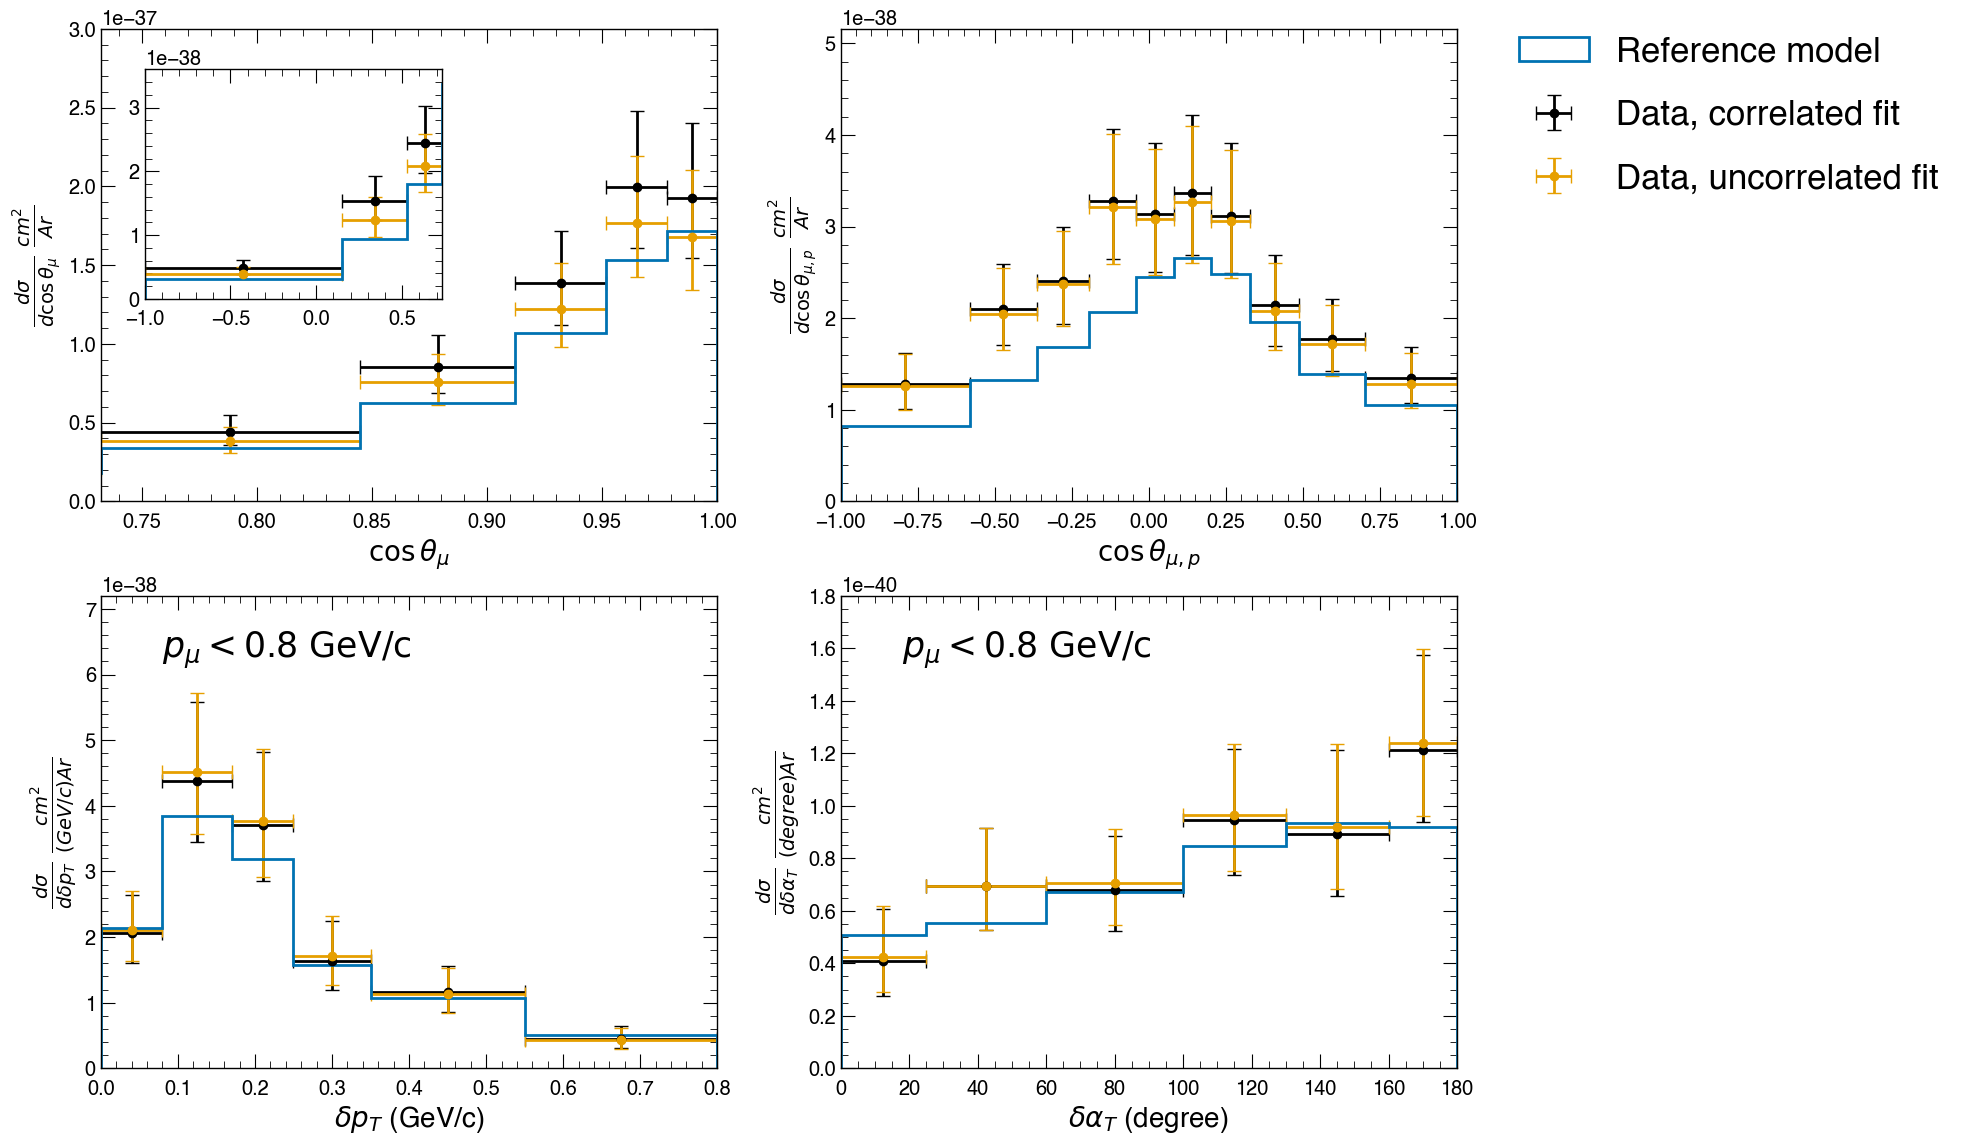

In [22]:
UseXsecToyUtil = True

fig_IndvSim_AnaBin, ax_IndvSim_AnaBin = plt.subplots(
    ncols=NVariables,
    nrows=2,
    figsize=(8*NVariables+1.5,2*6+1.5)
)

for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    IsMuonPCutApplied = ('MuonPLT0p8' in FitConfigType)
    PhaseSpaceCut = 'AllSignal'
    if IsMuonPCutApplied:
        PhaseSpaceCut = 'MuonPLT0p8'

    # Sim
    XsecFilepath = f'{XsecOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'
    # xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = CalcXsecFromThrows(XsecFilepath, VarType)
    xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = output_CalcXsecFromThrows[i_FitSet]

    for i_Variable, VariableName in enumerate(VariableNames):

        TrueVariableName = f'True{VariableName}'
        IsMuonCosPlot = ('MuonCos' in VariableName)

        variableInfo = variableInfos[TrueVariableName]
        VariableXTitle = variableInfo.GetXaxisTitle()
        xMin = variableInfo.xMin
        xMax = variableInfo.xMax

        VariableYTitle = CrossSectionPlotHelper.GetCrossSectionTitle(TrueVariableName)
        VariableYMax = CrossSectionPlotHelper.GetCrossSectionYMax(TrueVariableName, PhaseSpaceCut)

        if IsMuonCosPlot:

            y_boundary = 0.7320
            y_max_zoom = 0.12

            ax_IndvSim_AnaBin_zoom = fig_IndvSim_AnaBin.add_axes([0.15, 0.68, 0.17, 0.17])


        # Sim
        SubCovIndices = xsec_SubIndices[i_Variable]

        this_xsec_bestfit_vals = xsec_bestfit_vals[SubCovIndices]
        xsec_OneSig_XsecToyUtil = [xsec_dn_err[SubCovIndices], xsec_up_err[SubCovIndices]]

        with uproot.open(XsecFilepath) as f:

            # To get the binning
            h_for_binning = f[f'calcXsec/plots/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}/{TrueVariableName}/MC_TH1D']
            Binnings_Extraction = h_for_binning.to_numpy()[1]
            BinCenters_Extraction = [
                (Binnings_Extraction[i]+Binnings_Extraction[i+1])/2.
                for i in range(len(Binnings_Extraction)-1)
            ]
            BinErrors_Extraction = [
                (Binnings_Extraction[i+1]-Binnings_Extraction[i])/2.
                for i in range(len(Binnings_Extraction)-1)
            ]

            # x-sec hist
            uh_Extraction = f[f'calcXsec/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}_TH1D']
            h_Extraction = uh_Extraction.to_numpy()[0]
            h_Extraction_err = uh_Extraction.errors() if (not UseXsecToyUtil) else xsec_OneSig_XsecToyUtil

        ax_IndvSim_AnaBin[i_FitSet, i_Variable].errorbar(
            BinCenters_Extraction, 
            h_Extraction, 
            xerr=BinErrors_Extraction, 
            yerr=h_Extraction_err, 
            fmt='o',
            capsize=5,
            color='k',
            label='Data, correlated fit',
        )
        if IsMuonCosPlot:
            ax_IndvSim_AnaBin_zoom.errorbar(
                BinCenters_Extraction, 
                h_Extraction, 
                xerr=BinErrors_Extraction, 
                yerr=h_Extraction_err, 
                fmt='o',
                color='k',
                capsize=5,
            )
        
        # Indv        
        IndvFitConfigType = 'IndvFit_BarlowLLH' if VarType=='Angular' else 'IndvFit_MuonPLT0p8_BarlowLLH'
        XsecFilepath_Indv = f'{XsecOutputBaseDir}/output_{FitDataType}_{IndvFitConfigType}_{VariableName}.root'
        with uproot.open(XsecFilepath_Indv) as f:

            # x-sec hist
            uh_Extraction_Indv = f[f'calcXsec/histograms/TrueSignal_{PhaseSpaceCut}_{TrueVariableName}_TH1D']
            h_Extraction_Indv = uh_Extraction_Indv.to_numpy()[0]

            this_akarr_xsec = f['calcXsec/throws/xsecThrow_TTree'].arrays(library='ak')

            this_akarr_xsec = this_akarr_xsec[f'TrueSignal_{PhaseSpaceCut}_True{VariableName}']

            NToys = len(this_akarr_xsec)

            this_BinColNames = this_akarr_xsec.type.content.fields
            this_NXsecBin = len(this_BinColNames)

            this_arr_xsec = np.zeros((NToys, this_NXsecBin))
            for iBin in range(this_NXsecBin):
                this_arr_xsec[:,iBin] = this_akarr_xsec[this_BinColNames[iBin]].to_numpy()
            del this_akarr_xsec

            # this_arr_xsec: (NToys, NXsecBin)
            this_arr_xsec_log = np.log(this_arr_xsec)
            this_std_log = np.std(this_arr_xsec_log, axis=0)

            this_dn_log = np.log(h_Extraction_Indv)-this_std_log
            this_up_log = np.log(h_Extraction_Indv)+this_std_log
            
            this_dn = np.exp(this_dn_log)
            this_up = np.exp(this_up_log)


            h_Extraction_err_Indv = uh_Extraction_Indv.errors() if (not UseXsecToyUtil) else [h_Extraction_Indv-this_dn, this_up-h_Extraction_Indv]

        ax_IndvSim_AnaBin[i_FitSet, i_Variable].errorbar(
            BinCenters_Extraction, 
            h_Extraction_Indv, 
            xerr=BinErrors_Extraction, 
            yerr=h_Extraction_err_Indv, 
            fmt='o',
            capsize=5,
            color='#E69F00',
            label='Data, uncorrelated fit',
        )
        if IsMuonCosPlot:
                ax_IndvSim_AnaBin_zoom.errorbar(
                    BinCenters_Extraction, 
                    h_Extraction_Indv, 
                    xerr=BinErrors_Extraction, 
                    yerr=h_Extraction_err_Indv, 
                    fmt='o',
                    capsize=5,
                    color='#E69F00',
                )

        # Reference model
        TheoryBinType = 'AnaBin'
        this_csv = f'{TheoryXsecBaseDir}/xsec_{PhaseSpaceCut}_{GeneratorName}_{GeneratorConfig}_{GeneratorJobName}_True{VariableName}_{TheoryBinType}.csv'
        this_df = pd.read_csv(this_csv)
        BinCenters_Theory, BinErrors_Theory, h_Theory_AnaBin = this_df['x_center'].to_numpy(), this_df['x_err'].to_numpy(), this_df['xsec'].to_numpy()
        Binnings_Theory = BinCenters_Theory - BinErrors_Theory
        Binnings_Theory = np.append( Binnings_Theory, BinCenters_Theory[-1]+BinErrors_Theory[-1] )
        ax_IndvSim_AnaBin[i_FitSet,i_Variable].hist(
            Binnings_Theory[:-1], 
            bins=Binnings_Theory,
            weights=h_Theory_AnaBin,
            color='#0072B2',
            label='Reference model',
            histtype='step',
        )
        if IsMuonCosPlot:
            ax_IndvSim_AnaBin_zoom.hist(
                Binnings_Theory[:-1], 
                bins=Binnings_Theory,
                weights=h_Theory_AnaBin,
                color='#0072B2',
                histtype='step',
            )

        ax_IndvSim_AnaBin[i_FitSet, i_Variable].set_xlabel(VariableXTitle, fontsize=20)
        ax_IndvSim_AnaBin[i_FitSet, i_Variable].set_xlim(left=xMin, right=xMax)
        ax_IndvSim_AnaBin[i_FitSet, i_Variable].set_ylabel(VariableYTitle, fontsize=20)
        ax_IndvSim_AnaBin[i_FitSet, i_Variable].set_ylim(0., 1.2*VariableYMax)
        if IsMuonCosPlot:
            ax_IndvSim_AnaBin[i_FitSet, i_Variable].set_xlim(left=y_boundary, right=xMax)
            ax_IndvSim_AnaBin_zoom.set_xlim(left=xMin, right=y_boundary)
            ax_IndvSim_AnaBin_zoom.set_ylim(0., 1.2*VariableYMax*y_max_zoom)

        if IsMuonPCutApplied:
            cuttext_x_ratio = 0.10
            cuttext_y_ratio = 0.87

            _xrange = ax_IndvSim_AnaBin[i_FitSet, i_Variable].get_xlim()
            _use_x = _xrange[0] + cuttext_x_ratio*(_xrange[1] - _xrange[0])
            _yrange = ax_IndvSim_AnaBin[i_FitSet, i_Variable].get_ylim()
            _use_y = _yrange[0] + cuttext_y_ratio*(_yrange[1] - _yrange[0])

            ax_IndvSim_AnaBin[i_FitSet, i_Variable].text(_use_x, _use_y, r'$p_{\mu}<0.8~\mathrm{GeV/c}$', fontsize=25)

ax_IndvSim_AnaBin[0, 1].legend(
    fontsize=25,
    loc='upper left',
    bbox_to_anchor=(1.05, 1.05),
    labelspacing=0.9,
    ncols=1,
)

outputName = f'{IndvSimComparePlotDir}/xsec_AnaBin_Combined_Indv_vs_Sim.pdf'
if UseXsecToyUtil:
    outputName = f'{IndvSimComparePlotDir}/xsec_AnaBin_Combined_Indv_vs_Sim_WithToyUtil.pdf'
fig_IndvSim_AnaBin.savefig(outputName, bbox_inches='tight')

## Indv vs Sim, pulls

In [23]:
for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    # Sim
    FitterFile_Sim = f'{FitOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'
    ParamSetNames_Sim = []
    with uproot.open(FitterFile_Sim) as f:

        ErrorCalTDir = f[f'FitterEngine/postFit/Hesse']
        for k in ErrorCalTDir['errors']:
            if '/' in k:
                continue
            else:
                ParamSetName = k.split(';')[0]
                ParamSetNames_Sim.append(ParamSetName)

    for i_Variable, VariableName in enumerate(VariableNames):

        TrueVariableName = f'True{VariableName}'

        # Indv        
        IndvFitConfigType = 'IndvFit_BarlowLLH' if VarType=='Angular' else 'IndvFit_MuonPLT0p8_BarlowLLH'
        FitterFile_Indv = f'{FitOutputBaseDir}/output_{FitDataType}_{IndvFitConfigType}_{VariableName}.root'

        with uproot.open(FitterFile_Sim) as f_Sim, uproot.open(FitterFile_Indv) as f_Indv:

            for ParamSetName in ParamSetNames_Sim:

                if ParamSetName not in f_Indv[f'FitterEngine/postFit/Hesse/errors']:
                    continue
                
                histname = f'FitterEngine/postFit/Hesse/errors/{ParamSetName}/values/postFitErrors_TH1D'

                uh_Sim = f_Sim[histname]
                uh_Indv = f_Indv[histname]

                NThisParam = len(uh_Sim.to_numpy()[0])
                Binning = np.linspace(0, NThisParam, NThisParam+1)
                BinCenter = (Binning[:-1]+Binning[1:])/2.
                BinError = np.diff(Binning)/2.

                fig, ax = plt.subplots(figsize=(NThisParam, 5))

                ax.errorbar(
                    BinCenter,
                    uh_Sim.to_numpy()[0],
                    xerr=BinError,
                    yerr=uh_Sim.errors(),
                    fmt="o",
                    markersize=8,
                    capsize=3,
                    label='Correlated fit'
                )
                ax.errorbar(
                    BinCenter,
                    uh_Indv.to_numpy()[0],
                    xerr=BinError,
                    yerr=uh_Indv.errors(),
                    fmt="o",
                    markersize=8,
                    capsize=3,
                    label='Uncorrelated fit'
                )

                y_max = max(np.max(uh_Sim.to_numpy()[0]+uh_Sim.errors()), np.max(uh_Indv.to_numpy()[0]+uh_Indv.errors()))
                y_min = min(np.min(uh_Sim.to_numpy()[0]-uh_Sim.errors()), np.min(uh_Indv.to_numpy()[0]-uh_Indv.errors()))
                
                dy = y_max-y_min

                ax.set_ylim(y_min-0.3*dy, y_max+0.3*dy)

                if NThisParam==1:
                    ax.legend(loc='upper left', fontsize=10, bbox_to_anchor=(1.0, 1.0))
                else:
                    ax.legend(loc='upper right', fontsize=10)

                ax.minorticks_off()
                ax.set_xlim(Binning[0], Binning[-1])

                fig.suptitle(ParamSetName, va='bottom', y=0.90, fontsize=20)

                fig.savefig(f'{IndvSimComparePlotDir}/pulls_{VariableName}_{ParamSetName}.pdf', bbox_inches='tight')

                plt.close()


## Indv vs Sim, correlation

In [24]:
for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    # Sim
    FitterFile_Sim = f'{FitOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'

    for i_Variable, VariableName in enumerate(VariableNames):

        TrueVariableName = f'True{VariableName}'

        # Indv        
        IndvFitConfigType = 'IndvFit_BarlowLLH' if VarType=='Angular' else 'IndvFit_MuonPLT0p8_BarlowLLH'
        FitterFile_Indv = f'{FitOutputBaseDir}/output_{FitDataType}_{IndvFitConfigType}_{VariableName}.root'

        with uproot.open(FitterFile_Sim) as f_Sim, uproot.open(FitterFile_Indv) as f_Indv:

            uh_Cov_Sim = f_Sim[f'FitterEngine/postFit/Hesse/hessian/postfitCorrelation_TH2D']
            uh_Cov_Indv = f_Indv[f'FitterEngine/postFit/Hesse/hessian/postfitCorrelation_TH2D']

            BinLabels_Sim = uh_Cov_Sim.axis(0).labels()
            BinLabels_Indv = uh_Cov_Indv.axis(0).labels()

            CommonIndices = []
            for BinLabel_Indv in BinLabels_Indv:
                if BinLabel_Indv not in BinLabels_Sim:
                    print(BinLabel_Indv, 'NOT in Sim')
                    raise
                this_index = BinLabels_Sim.index(BinLabel_Indv)
                CommonIndices.append(this_index)
            CommonIndices = np.array(CommonIndices)

            NCovBin = len(CommonIndices)
            CovBinning = np.arange(NCovBin+1)

            h_Cov_Sim_Common = uh_Cov_Sim.to_numpy()[0][CommonIndices[:, None], CommonIndices]
            h_Cov_Indv = uh_Cov_Indv.to_numpy()[0]


            fig_Sim, ax_Sim = plt.subplots(figsize=(20, 20))
            mesh_Sim = ax_Sim.pcolormesh(
                CovBinning,
                CovBinning,
                h_Cov_Sim_Common.T,
                vmin=-1, vmax=1,
                cmap='coolwarm'
            )
            cbar_Sim = fig_Sim.colorbar(mesh_Sim, ax=ax_Sim, label='')
            fig_Sim.suptitle('Correlated fit', va='bottom', y=0.89, fontsize=50)
            fig_Sim.savefig(f'{IndvSimComparePlotDir}/CorrMat_{VariableName}_Sim.pdf', bbox_inches='tight')
            plt.close()

            fig_Indv, ax_Indv = plt.subplots(figsize=(20, 20))
            mesh_Indv = ax_Indv.pcolormesh(
                CovBinning,
                CovBinning,
                h_Cov_Indv.T,
                vmin=-1, vmax=1,
                cmap='coolwarm'
            )
            cbar_Indv = fig_Indv.colorbar(mesh_Indv, ax=ax_Indv, label='')
            fig_Indv.suptitle('Uncorrelated fit', va='bottom', y=0.89, fontsize=50)
            fig_Indv.savefig(f'{IndvSimComparePlotDir}/CorrMat_{VariableName}_Indv.pdf', bbox_inches='tight')
            plt.close()

# Test various covariance matrices for the data release

In [25]:
Chi2PlotDir = f'{OutputBaeDir}/chi2'
os.system(f'mkdir -p {Chi2PlotDir}')

0

0 Reference model 13.441432733640235 13.367965433464281 7.861477860343545
1 LQCD $z$-exp $F_{A}^{CCQE}$ 7.27187489353154 7.106998324522955 5.71704764105806
2 MINERvA $z$-exp $F_{A}^{CCQE}$ 9.404497895646514 9.316691442325018 6.226842225491868
3 hN2018 FSI 12.78660670164983 12.726077411765665 8.760885675683376
4 NEUT 23.021174614015404 22.916556514563855 14.157390854750354
5 NuWro 17.342686030110436 17.14290854349082 9.888422511424016
6 GiBUU 15.87649950815543 15.920086082880802 10.370535171894876
Fake theory 1.572936849267836 1.2492655184833332
0 Reference model 4.443663298843003 4.52478778520293 3.5479643153268507
1 LQCD $z$-exp $F_{A}^{CCQE}$ 4.582155728478703 4.669425036676233 5.350503881820063
2 MINERvA $z$-exp $F_{A}^{CCQE}$ 4.148611637034309 4.238788487392732 3.944630939187781
3 hN2018 FSI 4.887254731700862 4.970258488922271 4.947859983644168
4 NEUT 5.565069175717983 5.602850043795201 4.774976357944654
5 NuWro 13.728567690324224 13.561527986457186 10.64186437143097
6 GiBUU 13.378

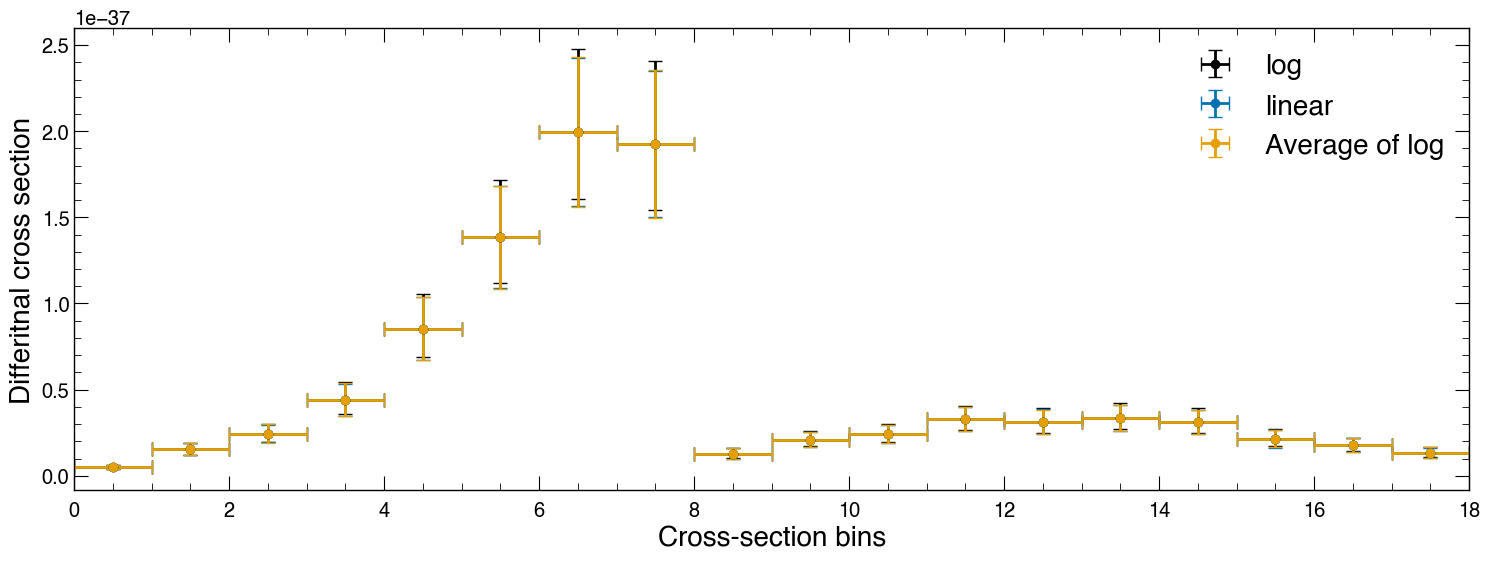

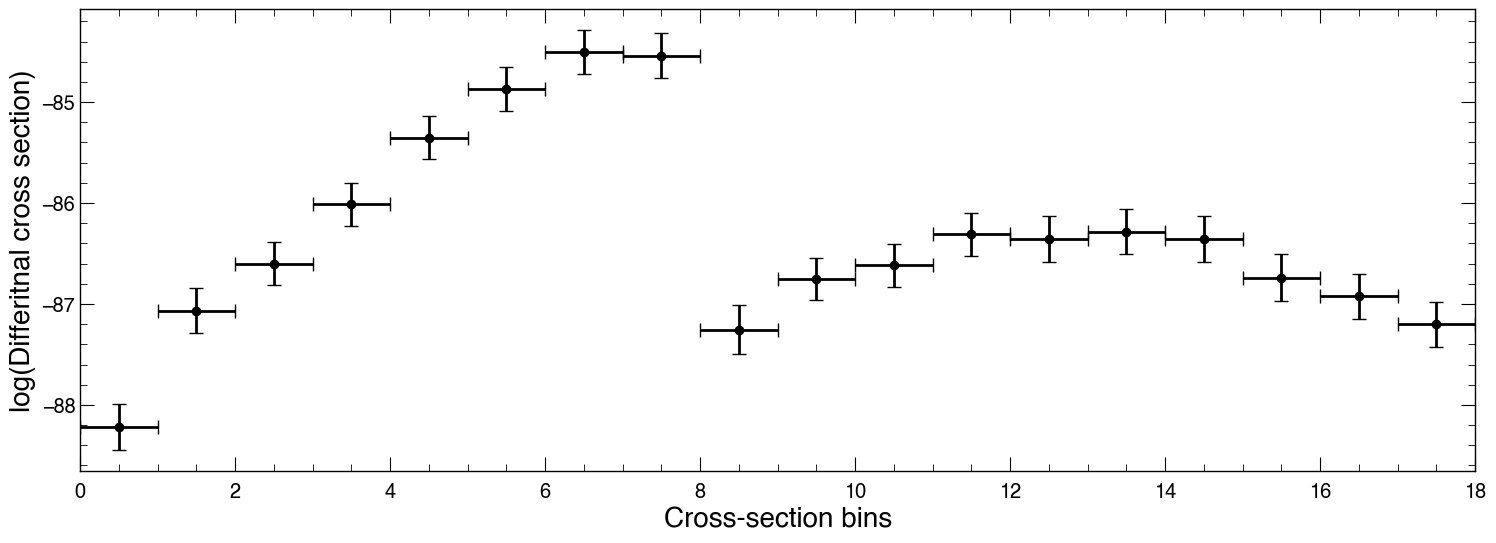

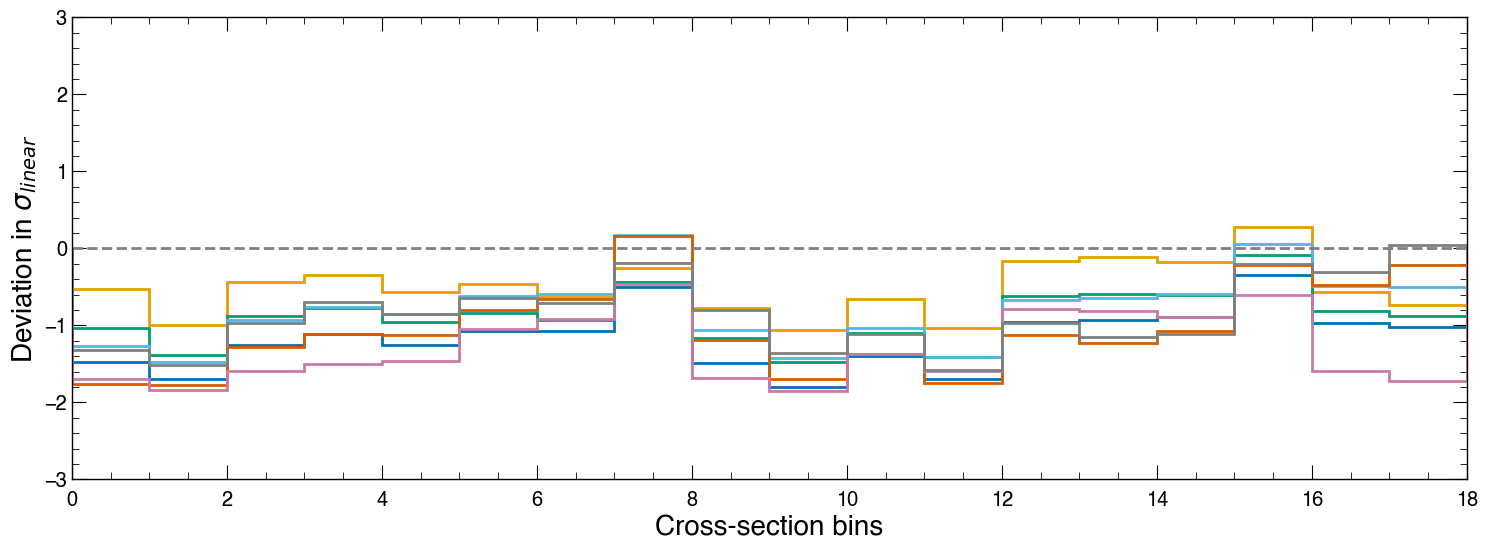

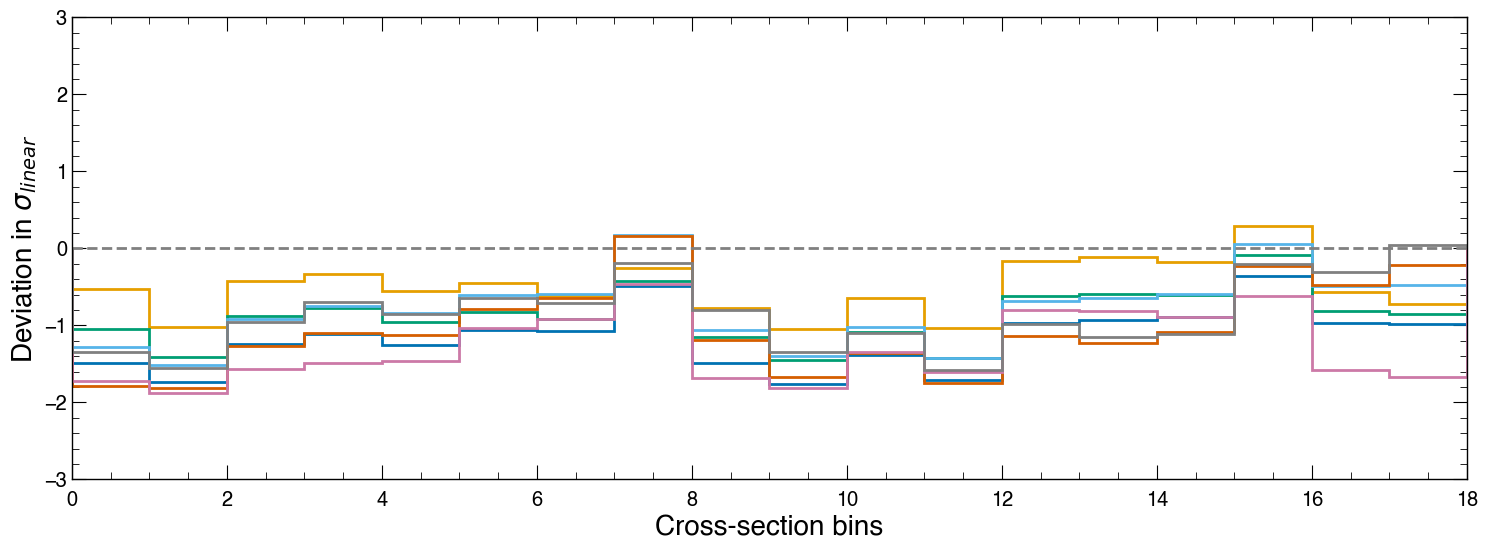

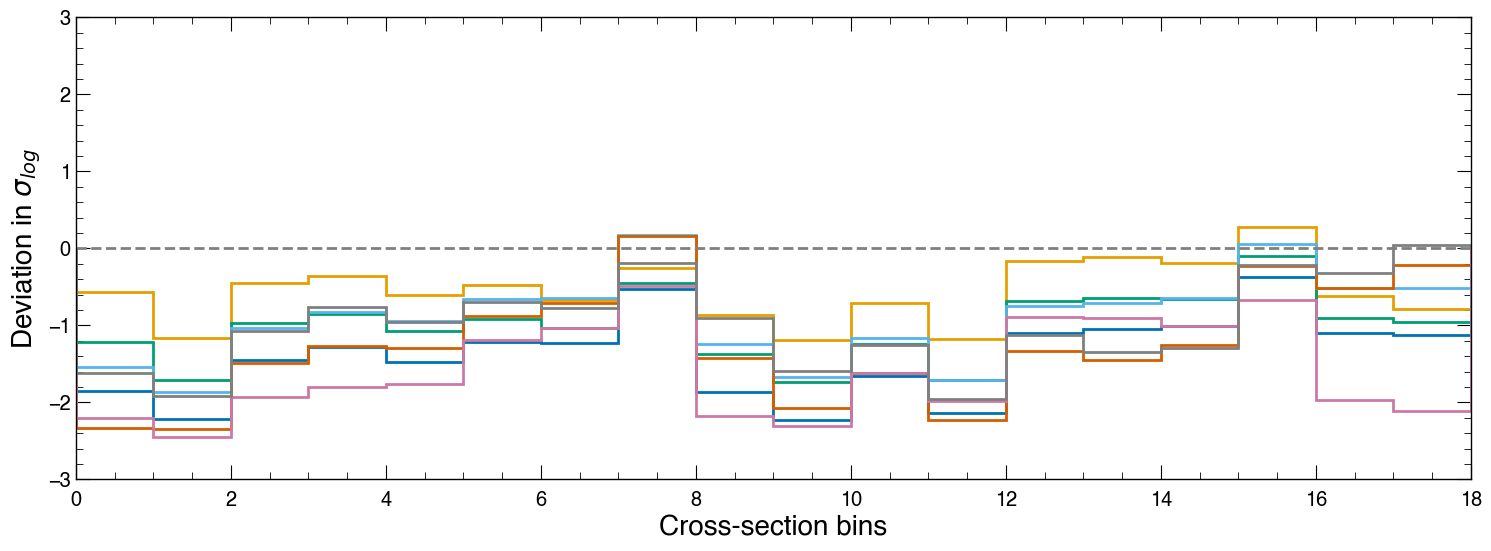

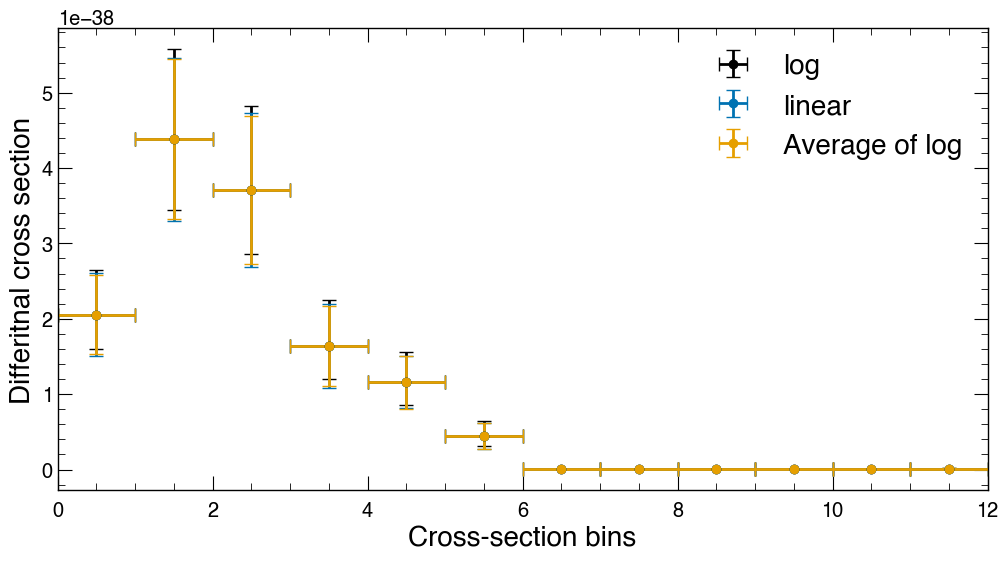

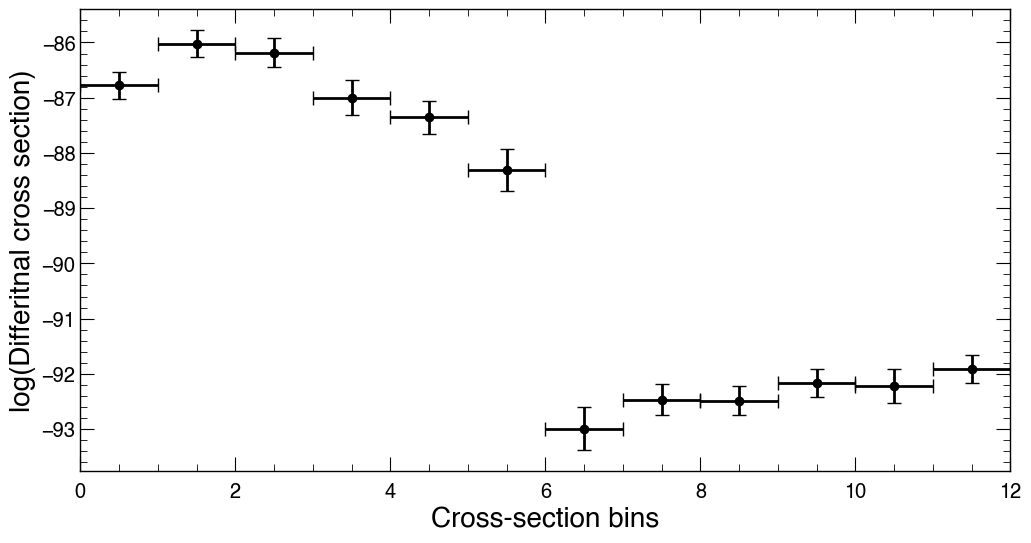

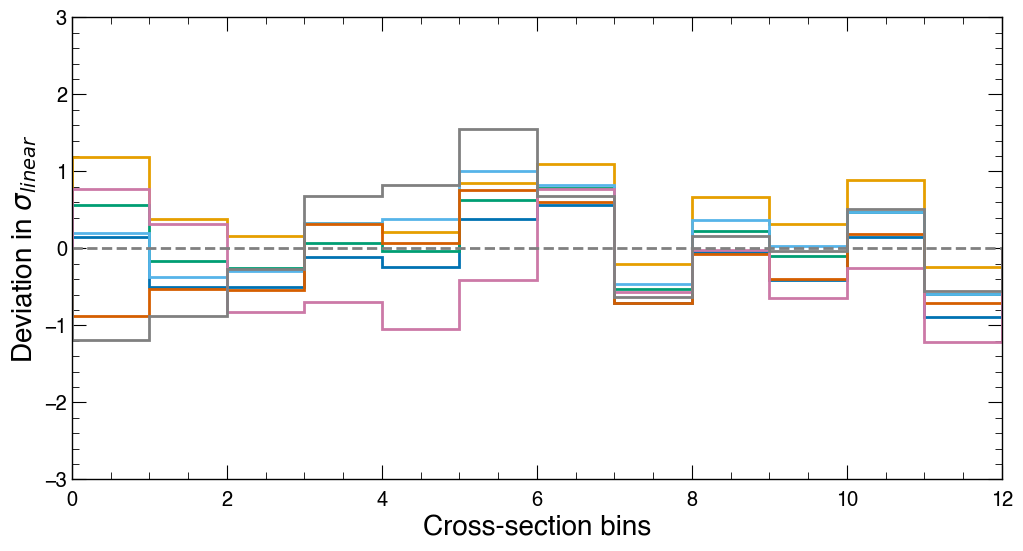

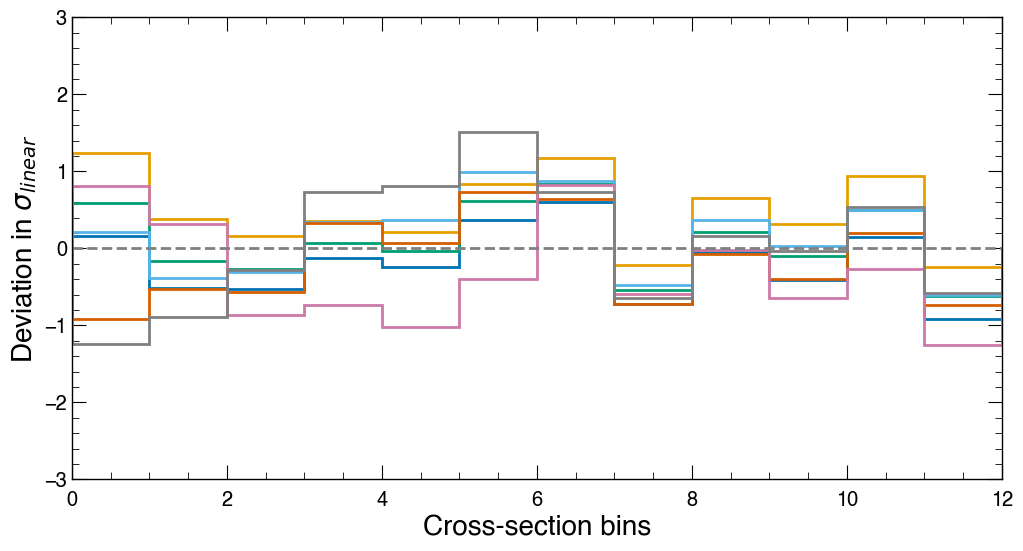

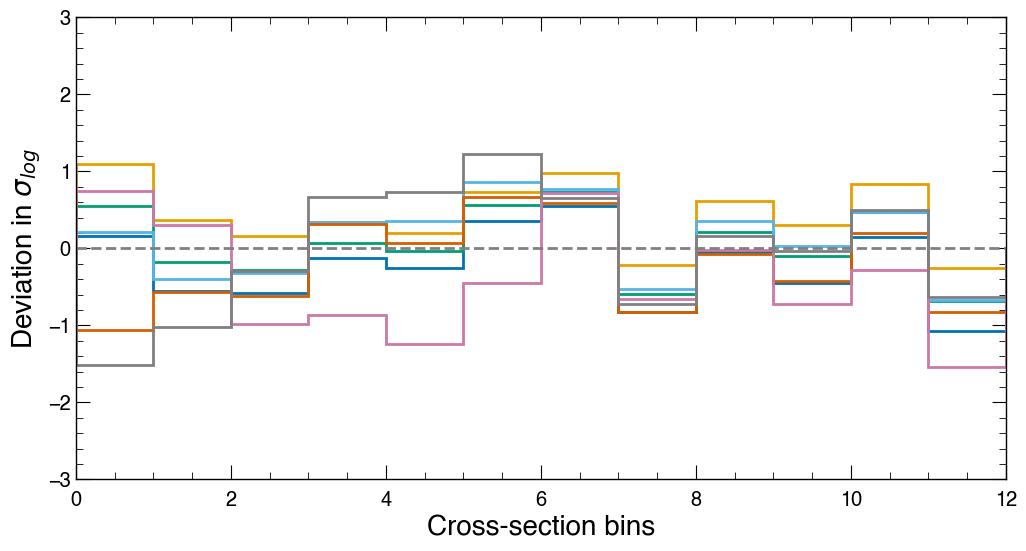

In [26]:
for i_FitSet, FitSet in enumerate(FitSets):

    VarType = FitSet[0]
    FitConfigType = FitSet[1]
    VariableNames = FitSet[2]

    VariableXName = VariableNames[0]
    VariableYName = VariableNames[1]

    IsMuonPCutApplied = ('MuonPLT0p8' in FitConfigType)
    PhaseSpaceCut = 'AllSignal'
    if IsMuonPCutApplied:
        PhaseSpaceCut = 'MuonPLT0p8'

    XsecFilepath = f'{XsecOutputBaseDir}/output_{FitDataType}_{FitConfigType}_{VariableXName}_and_{VariableYName}.root'

    # 1) Cov from log-scale (Most correct)
    xsec_cov_log, xsec_bestfit_vals, (xsec_dn_err, xsec_up_err), xsec_NXSecBin, xsec_SubIndices = output_CalcXsecFromThrows[i_FitSet]
    xsec_diagerr_log = np.sqrt(np.diag(xsec_cov_log))
    xsec_corr_log = xsec_cov_log / (xsec_diagerr_log[:,np.newaxis]*xsec_diagerr_log[np.newaxis,:])
    # 2) Cov from linear-scale 
    with uproot.open(XsecFilepath) as f:
        xsec_cov_linear = f['calcXsec/matrices/covarianceMatrix_TH2D'].to_numpy()[0]
    xsec_diagerr_linear = np.sqrt(np.diag(xsec_cov_linear))
    xsec_corr_linear = xsec_cov_linear / (xsec_diagerr_linear[:,np.newaxis] * xsec_diagerr_linear[np.newaxis,:])
    # 3) Use correlation from linear, but update diagonal to average from log-scale
    xsec_AvgLogErr = (xsec_dn_err+xsec_up_err)/2.
    # xsec_AvgLogErr = xsec_dn_err
    xsec_cov_CorrFromLinear_AvgLogErr = xsec_corr_linear * (xsec_AvgLogErr[:,np.newaxis]*xsec_AvgLogErr[np.newaxis,:])
    # 4) Use correlation from log, but update diagonal to average from log-scale
    xsec_cov_CorrFromLog_AvgLogErr = xsec_corr_log * (xsec_AvgLogErr[:,np.newaxis]*xsec_AvgLogErr[np.newaxis,:])

    NXsecBinAll = np.sum(xsec_NXSecBin)
    XsecBinning = np.arange(NXsecBinAll+1)
    XsecBinCenter = (XsecBinning[:-1]+XsecBinning[1:])/2.
    XsecBinError = np.diff(XsecBinning)/2.

    # data

    xsec_data_linear = xsec_bestfit_vals
    xsec_data_log = np.log(xsec_bestfit_vals)

    xsec_data_err_log = (np.log(xsec_bestfit_vals+xsec_up_err)-np.log(xsec_bestfit_vals))

    # Data error illustration
    fig_linear, ax_linear = plt.subplots(figsize=(NXsecBinAll, 6))
    fig_log, ax_log = plt.subplots(figsize=(NXsecBinAll, 6))

    ax_linear.errorbar(
        x=XsecBinCenter,
        xerr=XsecBinError,
        y=xsec_data_linear,
        yerr=(xsec_dn_err, xsec_up_err),
        fmt='o',
        capsize=5,
        color='k',
        label='log'
    )
    ax_linear.errorbar(
        x=XsecBinCenter,
        xerr=XsecBinError,
        y=xsec_data_linear,
        yerr=xsec_diagerr_linear,
        fmt='o',
        capsize=5,
        label='linear'
    )
    ax_linear.errorbar(
        x=XsecBinCenter,
        xerr=XsecBinError,
        y=xsec_data_linear,
        yerr=(xsec_dn_err+xsec_up_err)/2.,
        fmt='o',
        capsize=5,
        label='Average of log'
    )


    ax_linear.set_xlim(XsecBinning[0], XsecBinning[-1])
    ax_linear.set_xlabel('Cross-section bins', fontsize=20)

    # ax_linear.set_ylim(-3, 3)
    ax_linear.set_ylabel('Differitnal cross section', fontsize=20)

    ax_linear.legend(loc='upper right', fontsize=20)

    fig_linear.savefig(f'{Chi2PlotDir}/{VarType}_xsec_linear.pdf', bbox_inches='tight')    

    ax_log.errorbar(
        x=XsecBinCenter,
        xerr=XsecBinError,
        y=xsec_data_log,
        yerr=xsec_data_err_log,
        fmt='o',
        capsize=5,
        color='k',
        label='log',
    )

    ax_log.set_xlim(XsecBinning[0], XsecBinning[-1])
    ax_log.set_xlabel('Cross-section bins', fontsize=20)

    # ax_log.set_ylim(-3, 3)
    ax_log.set_ylabel('log(Differitnal cross section)', fontsize=20)

    fig_log.savefig(f'{Chi2PlotDir}/{VarType}_xsec_log.pdf', bbox_inches='tight')


    arr_xsec_theory_AnaBin = []
    for i_G, GeneratorInfo in enumerate(GeneratorInfos):

        GeneratorName = GeneratorInfo[0]
        GeneratorJobName = GeneratorInfo[1]
        GeneratorConfig = GeneratorInfo[2]
        GeneratorLatex = GeneratorInfo[3]

        this_arr_xsec_theory_AnaBin = np.array([])
        for i_Variable, VariableName in enumerate(VariableNames):

            TrueVariableName = f'True{VariableName}'

            variableInfo = variableInfos[TrueVariableName]
 
            Binnings_Extraction = xsec_Binnings_Extraction[i_Variable]

            # Ana binning
            TheoryBinType = 'AnaBin'
            this_csv = f'{TheoryXsecBaseDir}/xsec_{PhaseSpaceCut}_{GeneratorName}_{GeneratorConfig}_{GeneratorJobName}_True{VariableName}_{TheoryBinType}.csv'
            this_df = pd.read_csv(this_csv)
            BinCenters_Theory, BinErrors_Theory, h_Theory_AnaBin = this_df['x_center'].to_numpy(), this_df['x_err'].to_numpy(), this_df['xsec'].to_numpy()

            this_GlobalBinMask = xsec_SubIndices[i_Variable]
            this_bestfit_vals = xsec_bestfit_vals[this_GlobalBinMask]
            this_err = (xsec_dn_err[this_GlobalBinMask], xsec_up_err[this_GlobalBinMask])

            this_arr_xsec_theory_AnaBin = np.append(this_arr_xsec_theory_AnaBin, h_Theory_AnaBin)

        arr_xsec_theory_AnaBin.append(this_arr_xsec_theory_AnaBin)
    arr_xsec_theory_AnaBin = np.array(arr_xsec_theory_AnaBin)

    # Plotting

    fig_linear, ax_linear = plt.subplots(figsize=(NXsecBinAll, 6))
    fig_avglog, ax_avglog = plt.subplots(figsize=(NXsecBinAll, 6))
    fig_log, ax_log = plt.subplots(figsize=(NXsecBinAll, 6))

    for i_G, GeneratorInfo in enumerate(GeneratorInfos):

        GeneratorName = GeneratorInfo[0]
        GeneratorJobName = GeneratorInfo[1]
        GeneratorConfig = GeneratorInfo[2]
        GeneratorLatex = GeneratorInfo[3]

        this_xsec_theory_linear = arr_xsec_theory_AnaBin[i_G]
        this_xsec_theory_log = np.log(this_xsec_theory_linear)

        this_diff_linear = this_xsec_theory_linear - xsec_data_linear
        this_diff_log = this_xsec_theory_log - xsec_data_log

        # 1) diff in log
        this_diff_in_sigma_log = this_diff_log/xsec_data_err_log

        chi2_diff_log__corr_log = this_diff_in_sigma_log.T @ np.linalg.inv(xsec_corr_log) @ this_diff_in_sigma_log
        chi2_diff_log__corr_linear = this_diff_in_sigma_log.T @ np.linalg.inv(xsec_corr_linear) @ this_diff_in_sigma_log

        # 2) diff in linear
        # - Use linear covariance
        this_diff_in_sigma_linear = this_diff_linear/xsec_diagerr_linear

        chi2_diff_linear__corr_log = this_diff_in_sigma_linear.T @ np.linalg.inv(xsec_corr_log) @ this_diff_in_sigma_linear
        # - Use average of log
        this_diff_in_sigma_avglog = this_diff_linear/xsec_AvgLogErr
        
        print(i_G, GeneratorLatex, chi2_diff_log__corr_log, chi2_diff_log__corr_linear, chi2_diff_linear__corr_log)

        ax_log.hist(
            XsecBinning[:-1],
            bins=XsecBinning,
            weights=this_diff_in_sigma_log,
            histtype='step',
            label=GeneratorLatex,
        )

        ax_linear.hist(
            XsecBinning[:-1],
            bins=XsecBinning,
            weights=this_diff_in_sigma_linear,
            histtype='step',
            label=GeneratorLatex,
        )

        ax_avglog.hist(
            XsecBinning[:-1],
            bins=XsecBinning,
            weights=this_diff_in_sigma_avglog,
            histtype='step',
            label=GeneratorLatex,
        )

    # Fake theory value
    fake_theory_log = xsec_data_log - xsec_data_err_log
    fake_throy_linear = np.exp(fake_theory_log)

    this_diff_linear = fake_throy_linear - xsec_data_linear
    this_diff_log = fake_theory_log - xsec_data_log

    this_diff_in_sigma_log = this_diff_log/xsec_data_err_log

    chi2_diff_log__corr_log = this_diff_in_sigma_log.T @ np.linalg.inv(xsec_corr_log) @ this_diff_in_sigma_log

    this_diff_in_sigma_linear = this_diff_linear/xsec_diagerr_linear

    chi2_diff_linear__corr_log = this_diff_in_sigma_linear.T @ np.linalg.inv(xsec_corr_log) @ this_diff_in_sigma_linear

    print('Fake theory', chi2_diff_log__corr_log, chi2_diff_linear__corr_log)

    # Final touch

    ax_linear.set_xlim(XsecBinning[0], XsecBinning[-1])
    ax_linear.set_xlabel('Cross-section bins', fontsize=20)

    ax_linear.set_ylim(-3, 3)
    ax_linear.set_ylabel(r'Deviation in $\sigma_{linear}$', fontsize=20)

    ax_linear.axhline(0, color='gray', linestyle='--')

    fig_linear.savefig(f'{Chi2PlotDir}/{VarType}_diff_in_sigma_linear.pdf', bbox_inches='tight')

    ax_avglog.set_xlim(XsecBinning[0], XsecBinning[-1])
    ax_avglog.set_xlabel('Cross-section bins', fontsize=20)

    ax_avglog.set_ylim(-3, 3)
    ax_avglog.set_ylabel(r'Deviation in $\sigma_{linear}$', fontsize=20)

    ax_avglog.axhline(0, color='gray', linestyle='--')

    fig_avglog.savefig(f'{Chi2PlotDir}/{VarType}_diff_in_sigma_avglog.pdf', bbox_inches='tight')

    ax_log.set_xlim(XsecBinning[0], XsecBinning[-1])
    ax_log.set_xlabel('Cross-section bins', fontsize=20)

    ax_log.set_ylim(-3, 3)
    ax_log.set_ylabel(r'Deviation in $\sigma_{log}$', fontsize=20)

    ax_log.axhline(0, color='gray', linestyle='--')

    fig_log.savefig(f'{Chi2PlotDir}/{VarType}_diff_in_sigma_log.pdf', bbox_inches='tight')



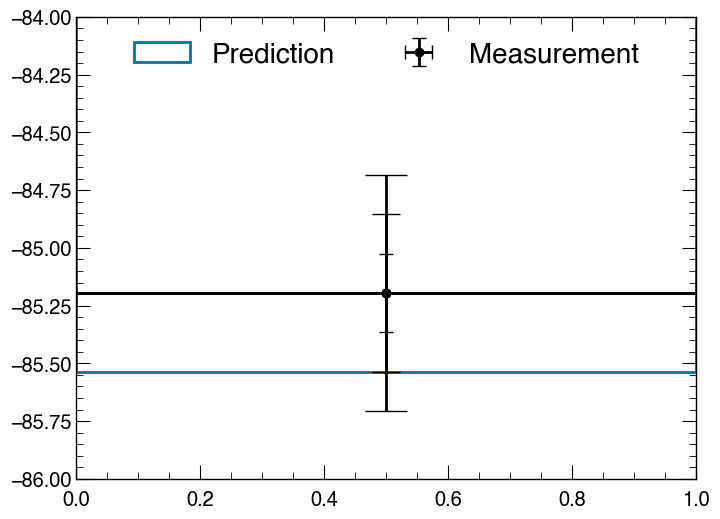

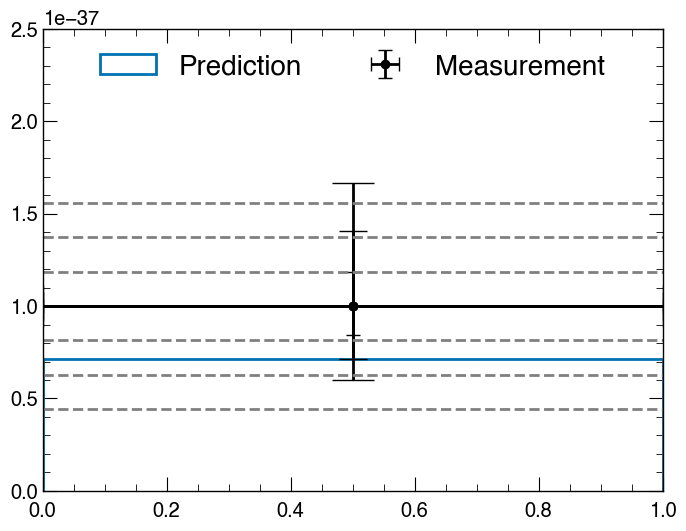

In [27]:
test_xsec_data_linear = 1E-37
test_xsec_data_log = np.log(test_xsec_data_linear)

test_xsec_data_relerr_log = 0.002
test_xsec_data_err_log = np.abs(test_xsec_data_log)*test_xsec_data_relerr_log

test_theory_log_sig_diff = -2.0
test_theory_log = test_xsec_data_log + test_theory_log_sig_diff * test_xsec_data_err_log

# Log

fig, ax = plt.subplots(figsize=(8,6))

test_Binning = np.linspace(0, 1, 1+1)

ax.hist(
    test_Binning[:-1],
    bins=test_Binning,
    weights=[test_theory_log],
    histtype='step',
    label='Prediction',
)
for i in [1,2,3]:
    label = 'Measurement' if i==1 else None
    ax.errorbar(
        x=[0.5],
        y=[test_xsec_data_log],
        xerr=0.5,
        yerr=test_xsec_data_err_log*i,
        fmt='ok',
        capsize=5*i,
        label=label,
    )

ax.set_xlim(0, 1)
ax.set_ylim(-86, -84)

ax.legend(loc='upper center', fontsize=20, ncols=2)

# Linear

fig, ax = plt.subplots(figsize=(8,6))

ax.hist(
    test_Binning[:-1],
    bins=test_Binning,
    weights=[np.exp(test_theory_log)],
    histtype='step',
    label='Prediction',
)
for i in [1,2,3]:
    label = 'Measurement' if i==1 else None
    this_logerr = test_xsec_data_err_log*i
    dn_err = [test_xsec_data_linear-np.exp(test_xsec_data_log-this_logerr)]
    up_err = [np.exp(test_xsec_data_log+this_logerr)-test_xsec_data_linear]

    ax.errorbar(
        x=[0.5],
        y=[np.exp(test_xsec_data_log)],
        xerr=0.5,
        yerr=[dn_err, up_err],
        fmt='ok',
        capsize=5*i,
        label=label,
    )

test_xsec_data_p1sig_log = test_xsec_data_log + test_xsec_data_err_log
test_xsec_data_m1sig_log = test_xsec_data_log - test_xsec_data_err_log
test_xsec_data_p1sig_linear = np.exp(test_xsec_data_p1sig_log)
test_xsec_data_m1sig_linear = np.exp(test_xsec_data_m1sig_log)
test_xsec_data_logavgerr =  (test_xsec_data_p1sig_linear-test_xsec_data_m1sig_linear)/2.
test_xsec_data_logavgerr = test_xsec_data_p1sig_linear-test_xsec_data_linear
for i in [1,2,3]:
    label = 'Measurement' if i==1 else None

    ax.axhline(test_xsec_data_linear+i*test_xsec_data_logavgerr, color='gray', linestyle='--')
    ax.axhline(test_xsec_data_linear-i*test_xsec_data_logavgerr, color='gray', linestyle='--')


ax.set_xlim(0, 1)
ax.set_ylim(0, 2.5E-37)

ax.legend(loc='upper center', fontsize=20, ncols=2)

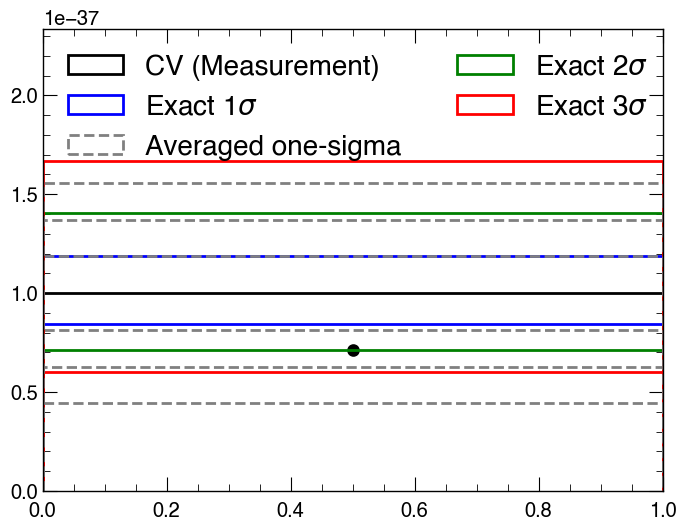

In [28]:
# Linear

fig, ax = plt.subplots(figsize=(8,6))

test_Binning = np.linspace(0, 1, 1+1)

ax.hist(
    test_Binning[:-1],
    bins=test_Binning,
    weights=[test_xsec_data_linear],
    histtype='step',
    color='k',
    label='CV (Measurement)',
)

test_xsec_data_p1sig_log = test_xsec_data_log + test_xsec_data_err_log
test_xsec_data_m1sig_log = test_xsec_data_log - test_xsec_data_err_log
test_xsec_data_p1sig_linear = np.exp(test_xsec_data_p1sig_log)
test_xsec_data_m1sig_linear = np.exp(test_xsec_data_m1sig_log)
test_xsec_data_logavgerr =  (test_xsec_data_p1sig_linear-test_xsec_data_m1sig_linear)/2.
test_xsec_data_logavgerr = test_xsec_data_p1sig_linear-test_xsec_data_linear

ups_log = []
dns_log = []
y_max = 0
for v, ThisColor in zip([1,2,3], ['b', 'g', 'r']):

    test_xsec_data_up_log = test_xsec_data_log + v*test_xsec_data_err_log
    test_xsec_data_dn_log = test_xsec_data_log - v*test_xsec_data_err_log

    test_xsec_data_up_linear = np.exp(test_xsec_data_up_log)
    test_xsec_data_dn_linear = np.exp(test_xsec_data_dn_log)

    this_exact_label=r'Exact %d$\sigma$'%(v)
    ax.hist(
        test_Binning[:-1],
        bins=test_Binning,
        weights=[test_xsec_data_up_linear],
        histtype='step',
        color=ThisColor,
        label=this_exact_label,
    )
    ax.hist(
        test_Binning[:-1],
        bins=test_Binning,
        weights=[test_xsec_data_dn_linear],
        histtype='step',
        color=ThisColor,
    )

    y_max = max(y_max, np.max(test_xsec_data_dn_linear))

    this_average_label='Averaged one-sigma' if v==1 else None
    ax.hist(
        test_Binning[:-1],
        bins=test_Binning,
        weights=[test_xsec_data_linear + v*test_xsec_data_logavgerr],
        histtype='step',
        color='gray',
        linestyle='--',
        label=this_average_label,
    )
    ax.hist(
        test_Binning[:-1],
        bins=test_Binning,
        weights=[test_xsec_data_linear - v*test_xsec_data_logavgerr],
        histtype='step',
        color='gray',
        linestyle='--',
    )

    y_max = max(y_max, np.max(test_xsec_data_linear + v*test_xsec_data_logavgerr))
    
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.5*y_max)

test_theory_linear = np.exp(test_theory_log)
test_theory_diff_linear = test_theory_linear - test_xsec_data_linear
test_theory_linear_sig_diff = test_theory_diff_linear/test_xsec_data_logavgerr
ax.scatter([0.5], [test_theory_linear], color='k', s=50)

ax.legend(loc='upper left', fontsize=20, ncols=2)